<a href="https://www.kaggle.com/code/avikdas567/era5-fire-weather-ablation-mesogeos-handofflstm?scriptVersionId=373787997" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Quantifying the Marginal Predictive Value of External ERA5 Atmospheric and Soil Modalities in MESOGEOS `HandoffLSTM`

---

# Scientific Objective and Experimental Design

This notebook presents a complete, reproducible solution for the **MeDiTwin: Extending the Modalities of the MESOGEOS Model** competition. The scientific objective is to determine whether augmenting the 24-variable MESOGEOS Track A `HandoffLSTM` wildfire-danger forecasting baseline with **exactly one additional interpretable scalar predictor from an external data source** improves next-day ignition forecasting, while holding the model architecture, random seed (`12345`), preprocessing, split membership, and 30-epoch optimization schedule strictly fixed.

Each sample consists of 30 consecutive daily observations (`time_idx = 0..29`) at one Mediterranean geographic coordinate, predicting whether a qualifying wildfire ignition ($\ge 30\text{ ha}$ final burned area) occurs on the target day (`time_idx = 30`, excluded from inputs). Submissions are ranked by **Area Under the Precision-Recall Curve (AUPRC)**:

$$\mathrm{Precision}(\tau) = \frac{\mathrm{TP}(\tau)}{\mathrm{TP}(\tau) + \mathrm{FP}(\tau)}, \qquad \mathrm{Recall}(\tau) = \frac{\mathrm{TP}(\tau)}{\mathrm{TP}(\tau) + \mathrm{FN}(\tau)}, \qquad \mathrm{AUPRC} = \int_0^1 \mathrm{Precision}(r)\,dr$$

Checkpoint selection on the validation split (`2,262` samples) is governed by minimum weighted negative log-likelihood:

$$\mathcal{L}_w = \frac{1}{N}\sum_{i=1}^{N} w_i \left[ -y_i \log\left(p_i + \epsilon\right) - (1 - y_i)\log\left(1 - p_i + \epsilon\right) \right], \qquad \epsilon = 10^{-6}$$

## Methodological Pipeline
1. **Bundle Reconstruction & Deterministic Environment**: Reconstruct `/kaggle/working/participant_bundle` from `/kaggle/input/competitions/mesogeos-plus-one`, enforce deterministic seeding (`12345`), and suppress non-actionable library warnings.
2. **Data Integrity & Covariate-Shift Diagnostics**: Audit sequence completeness, satellite-derived missingness (`smi`, `lai`, `ndvi`), spatial-temporal coverage (`2006–2022`), and distribution drift across Train, Validation, and Test splits using two-sample Kolmogorov-Smirnov ($D_{\mathrm{KS}}$) and Wasserstein-1 ($W_1$) metrics.
3. **Class-Conditional Statistical & Trajectory Analysis**: Quantify pre-ignition meteorological and vegetation anomalies over `time_idx = 0..29` using Mann-Whitney U tests, Benjamini-Hochberg FDR correction, Cliff's $\delta$ effect sizes, Spearman rank correlations, and Mutual Information.
4. **Control Baseline Verification**: Evaluate the official 24-variable control checkpoint (`clean_control_seed12345_state_dict.pt`, reference validation AUPRC = `0.90196645`, weighted loss = `1.14905264`).
5. **External NASA POWER (MERRA-2) Modality Retrieval & Controlled Ablation**: Retrieve four genuinely external, physically distinct daily predictors from the public **NASA POWER Agroclimatology (MERRA-2) Regional API** (`GWETTOP`, `GWETROOT`, `WS10M_MAX`, `T2M_RANGE`) aligned via `cKDTree` nearest-neighbor matching to MERRA-2's $0.5^\circ \times 0.625^\circ$ grid, and train each individually under the frozen 30-epoch `train_with_extra.py` pipeline.
6. **Statistical Significance, Calibration & Temporal Attribution**: Select the highest-AUPRC candidate using 2,000-resample paired bootstrap $\Delta\mathrm{AUPRC}$ confidence intervals, inspect reliability calibration and stratified seasonal/biogeographic gains, and compute Gradient $\times$ Input attributions across all 25 features and 30 timesteps.
7. **Submission Generation**: Produce and verify `/kaggle/working/submission.csv` via `predict_with_extra.py`.

# 1. Environment Setup, Reproducibility, and Kaggle Bundle Bootstrap

Kaggle mounts the 23 competition files into a flat read-only directory at `/kaggle/input/competitions/mesogeos-plus-one`. The supplied `baseline/` scripts expect sibling `data/` and `baseline/` directories. The bootstrap routine below symlinks large CSV files and copies Python modules, configuration files, and the official checkpoint into `/kaggle/working/participant_bundle`, with a local fallback outside Kaggle. Global determinism (`PYTHONHASHSEED=12345`, fixed NumPy/PyTorch seeds) and clean warning suppression are configured first.

In [1]:
import os
os.environ["PYTHONHASHSEED"] = "12345"
os.environ["PYTHONWARNINGS"] = "ignore"

from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import json
import random
import shutil
import subprocess
import sys
import time
import urllib.error
import urllib.request
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import requests
import scipy
from scipy import stats
from scipy.spatial import cKDTree
import sklearn
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.feature_selection import mutual_info_classif
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
import seaborn as sns

SEED = 12345
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

mpl.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 140,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
})

PALETTE_CLASS = {0: "#2b5c8f", 1: "#d95f02"}
PALETTE_SPLITS = {"Train": "#1b9e77", "Validation": "#7570b3", "Test": "#e7298a"}
PALETTE_MODELS = ["#4c72b0", "#dd8452", "#55a868", "#c44e52", "#8172b3", "#937860"]

print(f"Python:       {sys.version.split()[0]}")
print(f"PyTorch:      {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    for idx in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(idx)
        print(f"  GPU {idx}:      {props.name} ({props.total_memory / 1e9:.2f} GB)")
print(f"NumPy:        {np.__version__}")
print(f"Pandas:       {pd.__version__}")
print(f"SciPy:        {scipy.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

Python:       3.13.16
PyTorch:      2.11.0+cu130 | CUDA available: True
  GPU 0:      Tesla T4 (15.64 GB)
  GPU 1:      Tesla T4 (15.64 GB)
NumPy:        2.1.3
Pandas:       2.3.3
SciPy:        1.16.3
Scikit-learn: 1.6.1


In [2]:
def prepare_participant_bundle():
    kaggle_source = Path("/kaggle/input/competitions/mesogeos-plus-one")
    if not kaggle_source.is_dir():
        competition_root = Path("/kaggle/input/competitions")
        if competition_root.is_dir():
            candidates = [
                d for d in competition_root.iterdir()
                if d.is_dir() and (d / "train_sequences.csv").is_file() and (d / "model.py").is_file()
            ]
            if len(candidates) == 1:
                kaggle_source = candidates[0]

    local_candidates = [
        Path.cwd() / "mesogeos-plus-one",
        Path.cwd(),
        Path.cwd().parent / "mesogeos-plus-one",
    ]

    if kaggle_source.is_dir():
        source_root = kaggle_source
        target_root = Path("/kaggle/working/participant_bundle")
    else:
        source_root = next(
            (c for c in local_candidates if (c / "train_sequences.csv").is_file() and (c / "model.py").is_file()),
            None,
        )
        if source_root is None:
            raise FileNotFoundError(
                "Could not locate mesogeos-plus-one files in /kaggle/input/competitions/mesogeos-plus-one or local workspace."
            )
        target_root = Path.cwd() / "participant_bundle"

    file_groups = {
        "": ["README.md", "bundle_manifest.json"],
        "data": [
            "train_sequences.csv",
            "train_labels.csv",
            "validation_sequences.csv",
            "validation_labels.csv",
            "test_sequences.csv",
            "sample_submission.csv",
            "schema.json",
        ],
        "baseline": [
            "config.json",
            "model.py",
            "dataset.py",
            "model_factory.py",
            "extra_feature.py",
            "paths.py",
            "train_control.py",
            "train_with_extra.py",
            "predict_with_extra.py",
            "requirements.txt",
        ],
        "baseline/checkpoints": [
            "clean_control_seed12345_state_dict.pt",
            "training_history.csv",
            "training_summary.json",
        ],
        "notebooks": ["mesogeos_plus_one_starter.ipynb"],
    }

    copied = 0
    for rel_dir, filenames in file_groups.items():
        for fname in filenames:
            src = source_root / fname
            dst = target_root / rel_dir / fname
            if not src.is_file():
                raise FileNotFoundError(f"Missing expected competition file: {src}")
            dst.parent.mkdir(parents=True, exist_ok=True)
            if dst.is_symlink() or dst.is_file():
                dst.unlink()
            if src.suffix.lower() == ".csv":
                try:
                    dst.symlink_to(src)
                except OSError:
                    shutil.copy2(src, dst)
            else:
                shutil.copy2(src, dst)
            copied += 1

    return source_root, target_root, copied


SOURCE_ROOT, BUNDLE, FILE_COUNT = prepare_participant_bundle()
BASELINE = BUNDLE / "baseline"
DATA = BUNDLE / "data"
WORK = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd() / "working"
WORK.mkdir(parents=True, exist_ok=True)

if str(BASELINE) not in sys.path:
    sys.path.insert(0, str(BASELINE))

config = json.loads((BASELINE / "config.json").read_text())
schema = json.loads((DATA / "schema.json").read_text())

print(f"Source root:        {SOURCE_ROOT}")
print(f"Participant bundle: {BUNDLE} ({FILE_COUNT} files linked/copied)")
print(f"Working directory:  {WORK}")
print(f"Dynamic features ({len(config['dynamic_features'])}): {config['dynamic_features']}")
print(f"Static features  ({len(config['static_features'])}):  {config['static_features']}")
print(f"Satellite-derived forecast-excluded indices: {config['satellite_derived_dynamic_indices']}")

Source root:        /kaggle/input/competitions/mesogeos-plus-one
Participant bundle: /kaggle/working/participant_bundle (23 files linked/copied)
Working directory:  /kaggle/working
Dynamic features (12): ['d2m', 'lai', 'lst_day', 'lst_night', 'ndvi', 'rh', 'smi', 'sp', 'ssrd', 't2m', 'tp', 'wind_speed']
Static features  (12):  ['dem', 'roads_distance', 'slope', 'lc_agriculture', 'lc_forest', 'lc_grassland', 'lc_settlement', 'lc_shrubland', 'lc_sparse_vegetation', 'lc_water_bodies', 'lc_wetland', 'population']
Satellite-derived forecast-excluded indices: [1, 2, 3, 4, 6]


# 2. Data Integrity, Schema Verification, and Split Audit

We verify all structural invariants enforced by `MesogeosSequenceDataset` and `ExtraFeatureDataset`:
- Every `competition_id` spans exactly 30 consecutive daily rows (`time_idx = 0, \dots, 29`).
- Train (`2006–2019`), Validation (`2019–2020`), and Test (`2020–2022`) splits are chronologically partitioned with disjoint identifiers.
- `loss_weight` and `label` align one-to-one with `competition_id` in the training and validation splits, and `loss_weight` is strictly excluded from model inputs.

In [3]:
train_seq = pd.read_csv(DATA / "train_sequences.csv")
train_labels = pd.read_csv(DATA / "train_labels.csv")
val_seq = pd.read_csv(DATA / "validation_sequences.csv")
val_labels = pd.read_csv(DATA / "validation_labels.csv")
test_seq = pd.read_csv(DATA / "test_sequences.csv")
sample_sub = pd.read_csv(DATA / "sample_submission.csv")

for df in [train_seq, val_seq, test_seq]:
    df["time_dt"] = pd.to_datetime(df["time"])

audit_rows = []
for split_name, seq_df, lbl_df in [
    ("Train", train_seq, train_labels),
    ("Validation", val_seq, val_labels),
    ("Test", test_seq, None),
]:
    n_samples = seq_df["competition_id"].nunique()
    n_rows = len(seq_df)
    assert n_rows == n_samples * 30, f"{split_name}: row count not 30x samples"
    assert (seq_df.groupby("competition_id")["time_idx"].count() == 30).all()
    pos_rate = lbl_df["label"].mean() if lbl_df is not None else np.nan
    w_mean = lbl_df["loss_weight"].mean() if lbl_df is not None else np.nan
    audit_rows.append({
        "Split": split_name,
        "Samples": n_samples,
        "Rows": n_rows,
        "Start Date": seq_df["time_dt"].min().strftime("%Y-%m-%d"),
        "End Date": seq_df["time_dt"].max().strftime("%Y-%m-%d"),
        "Lon Min": round(seq_df["longitude"].min(), 3),
        "Lon Max": round(seq_df["longitude"].max(), 3),
        "Lat Min": round(seq_df["latitude"].min(), 3),
        "Lat Max": round(seq_df["latitude"].max(), 3),
        "Positive Rate": round(pos_rate, 4) if np.isfinite(pos_rate) else "Hidden",
        "Mean Loss Weight": round(w_mean, 4) if np.isfinite(w_mean) else "N/A",
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

train_merged = train_seq.merge(train_labels, on="competition_id", how="left", validate="many_to_one")
val_merged = val_seq.merge(val_labels, on="competition_id", how="left", validate="many_to_one")
print("Label merge verified. Test sample_submission rows:", len(sample_sub))

,Split,Samples,Rows,Start Date,End Date,Lon Min,Lon Max,Lat Min,Lat Max,Positive Rate,Mean Loss Weight
0,Train,19353,580590,2006-04-01,2019-12-31,-9.783,36.102,30.703,45.927,0.3333,4.0155
1,Validation,2262,67860,2019-12-03,2020-12-31,-9.712,36.102,30.763,45.706,0.3333,3.9214
2,Test,4107,123210,2020-12-03,2022-09-29,-9.601,36.081,30.713,45.907,Hidden,N/A


Label merge verified. Test sample_submission rows: 4107


# 3. Exploratory Data Analysis and Statistical Diagnostics

We characterize the physical, spatial, temporal, and statistical properties of the 24 baseline variables across the Mediterranean basin.

## 3.1 Missingness Structure Across Splits

Satellite-derived variables (`smi`, `lai`, `lst_day`, `lst_night`, `ndvi`) contain genuine missing observations caused by cloud cover, orbital swath gaps, and surface masking. Because `MesogeosSequenceDataset` imputes missing dynamic entries with the sample's 30-day standardized mean (or `0.0` if all 30 days are missing), shifts in missingness rate across splits directly affect effective feature variance.

,Train,Validation,Test
population,0.010,0.000,0.000
ndvi,0.207,0.398,0.110
lai,1.829,1.459,1.388
smi,15.576,2.210,2.362
lst_day,31.028,31.662,32.047
lst_night,35.802,36.208,37.534


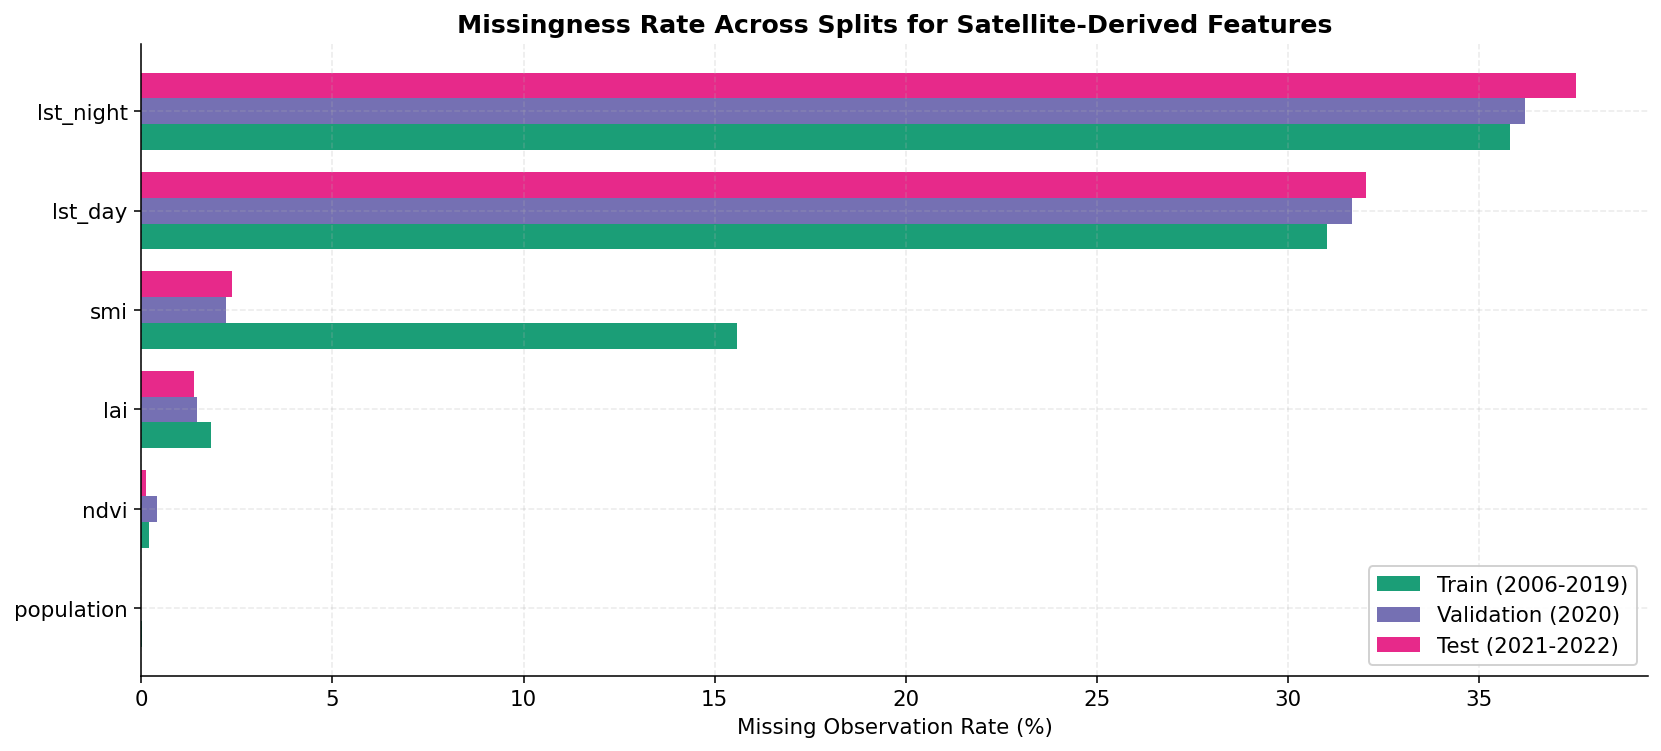

In [4]:
all_features = config["dynamic_features"] + config["static_features"]
miss_df = pd.DataFrame({
    "Train": train_seq[all_features].isna().mean() * 100.0,
    "Validation": val_seq[all_features].isna().mean() * 100.0,
    "Test": test_seq[all_features].isna().mean() * 100.0,
})
miss_nonzero = miss_df[miss_df.max(axis=1) > 0].sort_values("Train", ascending=True)
display(miss_nonzero.round(3))

fig, ax = plt.subplots(figsize=(12, 5.5))
y_pos = np.arange(len(miss_nonzero))
bar_h = 0.26
ax.barh(y_pos - bar_h, miss_nonzero["Train"], height=bar_h, color=PALETTE_SPLITS["Train"], label="Train (2006-2019)")
ax.barh(y_pos, miss_nonzero["Validation"], height=bar_h, color=PALETTE_SPLITS["Validation"], label="Validation (2020)")
ax.barh(y_pos + bar_h, miss_nonzero["Test"], height=bar_h, color=PALETTE_SPLITS["Test"], label="Test (2021-2022)")
ax.set_yticks(y_pos)
ax.set_yticklabels(miss_nonzero.index)
ax.set_xlabel("Missing Observation Rate (%)")
ax.set_title("Missingness Rate Across Splits for Satellite-Derived Features")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 3.2 Spatial Distribution Across the Mediterranean Basin

We inspect the geographic distribution of qualifying wildfire ignitions ($\ge 30\text{ ha}$) versus negative controls in the training split, followed by the spatial footprint of the validation and test splits.

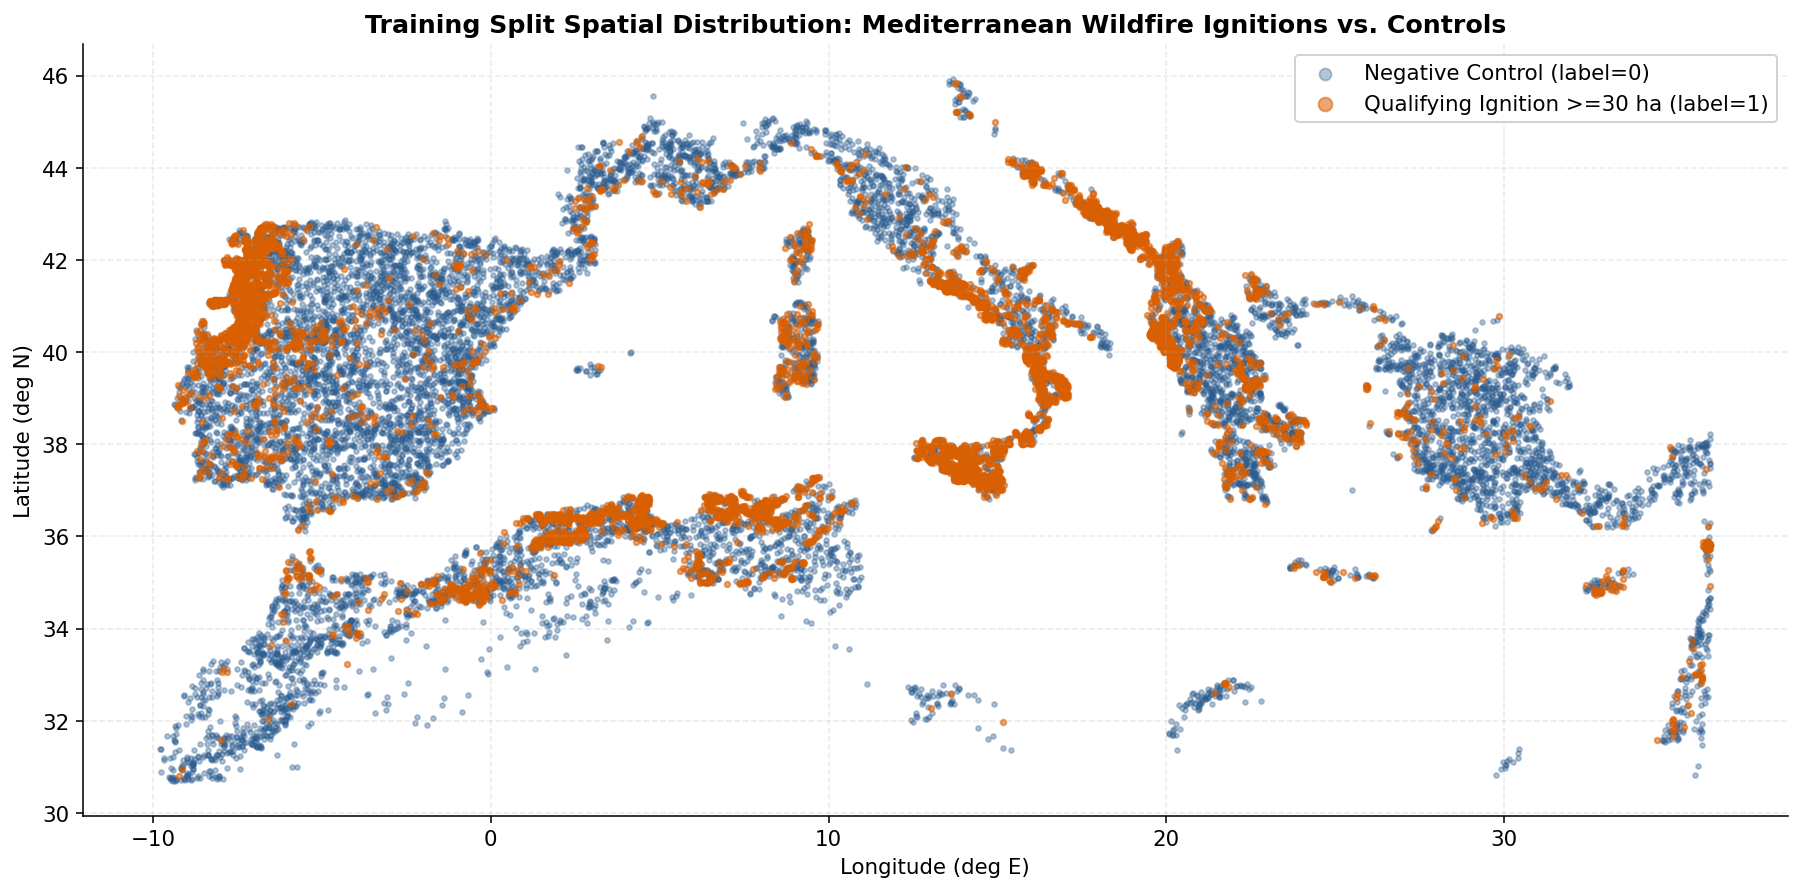

In [5]:
train_loc = train_merged[train_merged["time_idx"] == 29][["competition_id", "longitude", "latitude", "label"]]
val_loc = val_merged[val_merged["time_idx"] == 29][["competition_id", "longitude", "latitude", "label"]]
test_loc = test_seq[test_seq["time_idx"] == 29][["competition_id", "longitude", "latitude"]]

fig, ax = plt.subplots(figsize=(13, 6.5))
neg = train_loc[train_loc["label"] == 0]
pos = train_loc[train_loc["label"] == 1]
ax.scatter(neg["longitude"], neg["latitude"], s=6, alpha=0.35, color=PALETTE_CLASS[0], label="Negative Control (label=0)")
ax.scatter(pos["longitude"], pos["latitude"], s=8, alpha=0.55, color=PALETTE_CLASS[1], label="Qualifying Ignition >=30 ha (label=1)")
ax.set_xlabel("Longitude (deg E)")
ax.set_ylabel("Latitude (deg N)")
ax.set_title("Training Split Spatial Distribution: Mediterranean Wildfire Ignitions vs. Controls")
ax.legend(markerscale=2.5, loc="upper right")
plt.tight_layout()
plt.show()

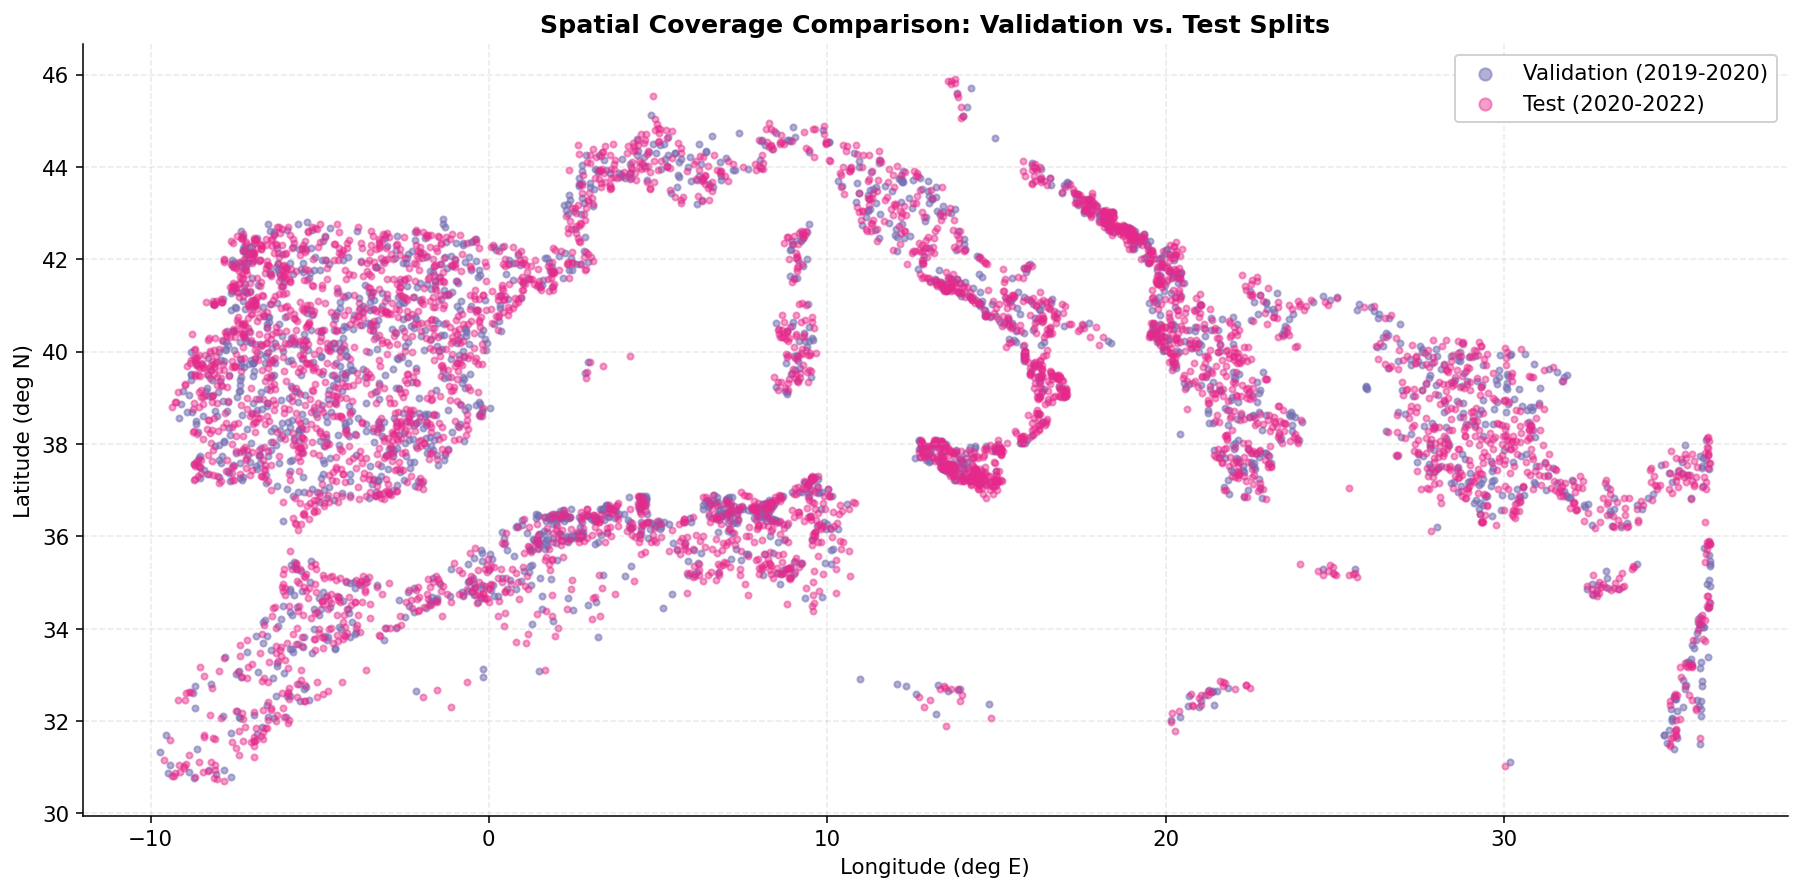

In [6]:
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.scatter(val_loc["longitude"], val_loc["latitude"], s=10, alpha=0.55, color=PALETTE_SPLITS["Validation"], label="Validation (2019-2020)")
ax.scatter(test_loc["longitude"], test_loc["latitude"], s=10, alpha=0.45, color=PALETTE_SPLITS["Test"], label="Test (2020-2022)")
ax.set_xlabel("Longitude (deg E)")
ax.set_ylabel("Latitude (deg N)")
ax.set_title("Spatial Coverage Comparison: Validation vs. Test Splits")
ax.legend(markerscale=2.0, loc="upper right")
plt.tight_layout()
plt.show()

## 3.3 Temporal and Seasonal Ignition Dynamics

Mediterranean wildfire activity peaks during June–September under persistent subtropical ridging and seasonal fuel curing. Note that calendar date (`time`) is excluded from the 24 baseline inputs.

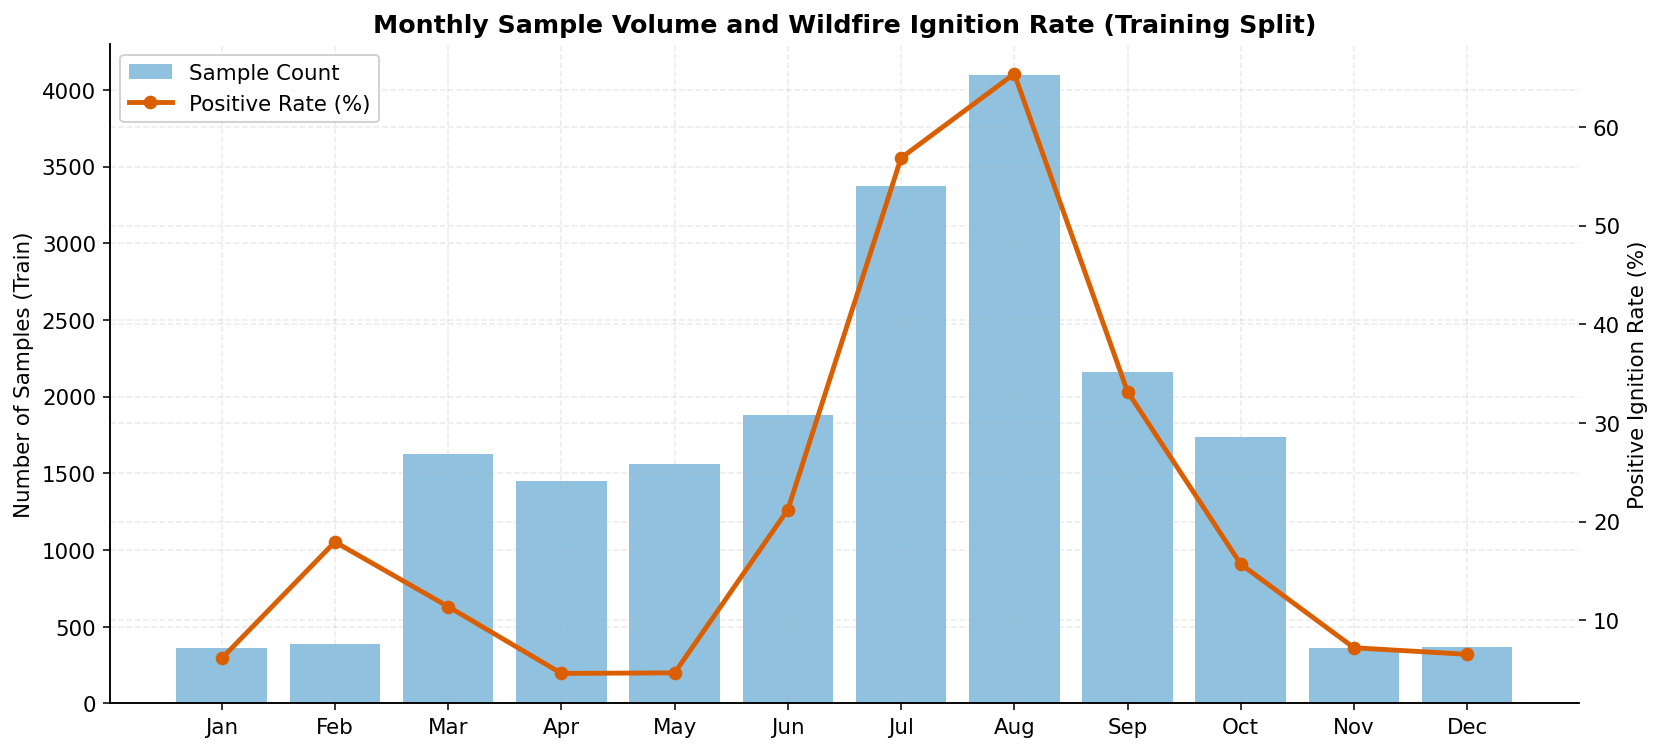

In [7]:
train_d29 = train_merged[train_merged["time_idx"] == 29].copy()
train_d29["month"] = train_d29["time_dt"].dt.month
train_d29["year"] = train_d29["time_dt"].dt.year
train_d29["doy"] = train_d29["time_dt"].dt.dayofyear

monthly_stats = train_d29.groupby("month").agg(
    samples=("label", "count"),
    pos_rate=("label", "mean"),
).reindex(range(1, 13), fill_value=0)

fig, ax1 = plt.subplots(figsize=(12, 5.5))
months = np.arange(1, 13)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax1.bar(months, monthly_stats["samples"], color="#6baed6", alpha=0.75, label="Sample Count")
ax1.set_xticks(months)
ax1.set_xticklabels(month_names)
ax1.set_ylabel("Number of Samples (Train)")
ax1.set_title("Monthly Sample Volume and Wildfire Ignition Rate (Training Split)")

ax2 = ax1.twinx()
ax2.spines["top"].set_visible(False)
ax2.plot(months, monthly_stats["pos_rate"] * 100.0, color="#d95f02", marker="o", linewidth=2.5, label="Positive Rate (%)")
ax2.set_ylabel("Positive Ignition Rate (%)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
plt.tight_layout()
plt.show()

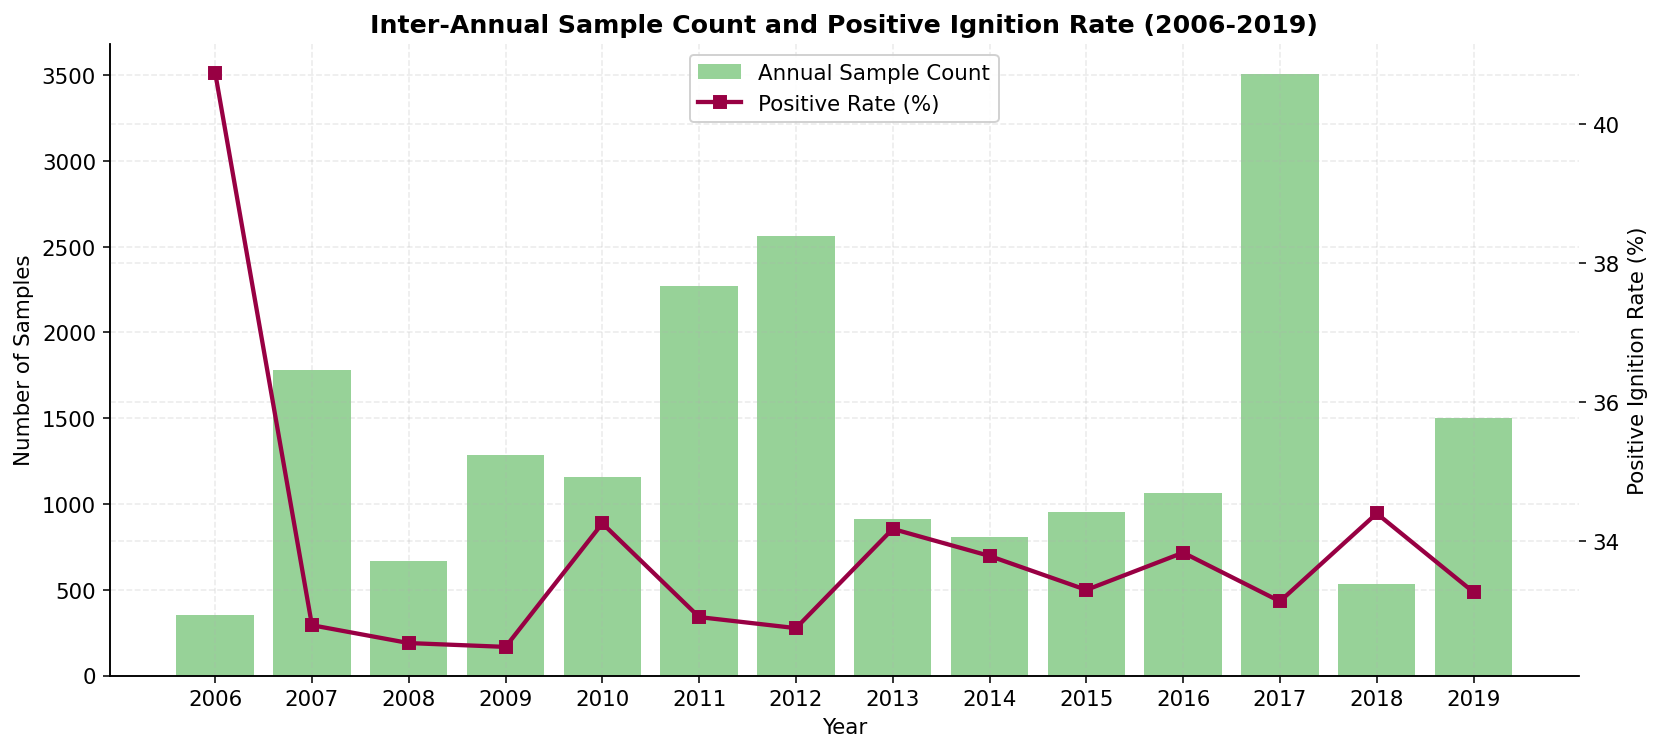

In [8]:
yearly_stats = train_d29.groupby("year").agg(
    samples=("label", "count"),
    pos_rate=("label", "mean"),
)

fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax1.bar(yearly_stats.index, yearly_stats["samples"], color="#74c476", alpha=0.75, label="Annual Sample Count")
ax1.set_xlabel("Year")
ax1.set_ylabel("Number of Samples")
ax1.set_title("Inter-Annual Sample Count and Positive Ignition Rate (2006-2019)")
ax1.set_xticks(yearly_stats.index)

ax2 = ax1.twinx()
ax2.spines["top"].set_visible(False)
ax2.plot(yearly_stats.index, yearly_stats["pos_rate"] * 100.0, color="#980043", marker="s", linewidth=2.2, label="Positive Rate (%)")
ax2.set_ylabel("Positive Ignition Rate (%)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper center")
plt.tight_layout()
plt.show()

## 3.4 Covariate Shift Diagnostics Across Chronological Splits

We measure distributional drift between Train (`2006-2019`), Validation (`2020`), and Test (`2021-2022`) using the two-sample Kolmogorov-Smirnov statistic:

$$D_{\mathrm{KS}}(F_{\mathrm{train}}, F_{\mathrm{test}}) = \sup_x \left| F_{\mathrm{train}}(x) - F_{\mathrm{test}}(x) \right|$$

and the standardized Wasserstein-1 earth-mover distance $W_1$.

,Feature,"KS(Train, Val)","KS(Train, Test)","Std Wasserstein(Train, Test)"
19,lc_shrubland,0.0211,0.0284,0.0545
6,smi,0.0300,0.0318,0.0710
7,sp,0.0319,0.0319,0.0478
5,rh,0.0409,0.0384,0.0683
11,wind_speed,0.0364,0.0448,0.0754
0,d2m,0.0372,0.0515,0.0908
8,ssrd,0.0284,0.0588,0.1014
9,t2m,0.0373,0.0621,0.1072
3,lst_night,0.0621,0.0959,0.1540
10,tp,0.1230,0.1007,0.0156


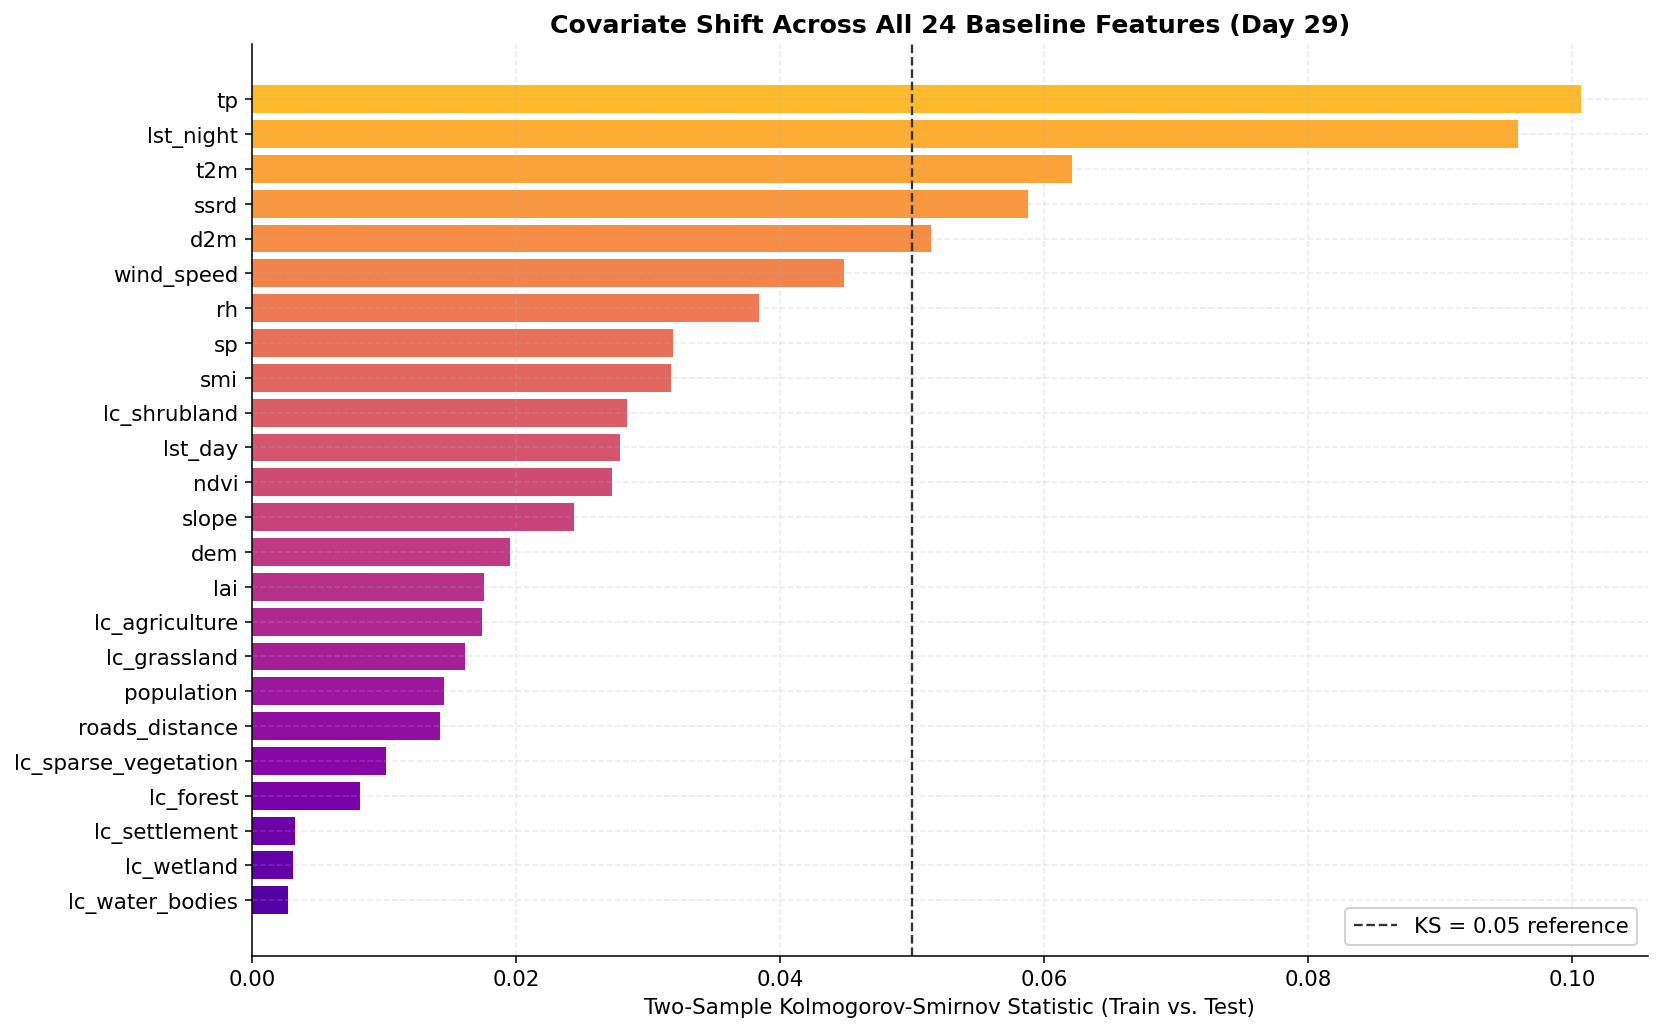

In [9]:
val_d29 = val_merged[val_merged["time_idx"] == 29].copy()
test_d29 = test_seq[test_seq["time_idx"] == 29].copy()

drift_rows = []
for feat in all_features:
    tr_v = train_d29[feat].dropna().to_numpy()
    va_v = val_d29[feat].dropna().to_numpy()
    te_v = test_d29[feat].dropna().to_numpy()
    ks_tv, _ = stats.ks_2samp(tr_v, va_v)
    ks_tt, _ = stats.ks_2samp(tr_v, te_v)
    w_tt = stats.wasserstein_distance(
        (tr_v - tr_v.mean()) / (tr_v.std() + 1e-8),
        (te_v - tr_v.mean()) / (tr_v.std() + 1e-8),
    )
    drift_rows.append({
        "Feature": feat,
        "KS(Train, Val)": ks_tv,
        "KS(Train, Test)": ks_tt,
        "Std Wasserstein(Train, Test)": w_tt,
    })

drift_df = pd.DataFrame(drift_rows).sort_values("KS(Train, Test)", ascending=True)
display(drift_df.tail(10).round(4))

fig, ax = plt.subplots(figsize=(12, 7.5))
colors_drift = plt.cm.plasma(np.linspace(0.15, 0.85, len(drift_df)))
ax.barh(drift_df["Feature"], drift_df["KS(Train, Test)"], color=colors_drift)
ax.axvline(0.05, color="#333333", linestyle="--", linewidth=1.2, label="KS = 0.05 reference")
ax.set_xlabel("Two-Sample Kolmogorov-Smirnov Statistic (Train vs. Test)")
ax.set_title("Covariate Shift Across All 24 Baseline Features (Day 29)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 3.5 Class-Conditional Statistical Hypothesis Testing

To quantify univariate separation between ignition events ($Y=1$) and negative controls ($Y=0$) at `time_idx = 29`, we compute two-sided Mann-Whitney U $p$-values with Benjamini-Hochberg FDR adjustment and Cliff's $\delta$ effect size:

$$\delta = \frac{2U}{n_1 n_0} - 1 \in [-1, 1]$$

,Feature,Type,Pos Mean,Neg Mean,Cliffs_Delta,Abs_Delta,p_value,FDR_q
9,t2m,Dynamic,3.038261e+02,2.955587e+02,0.59931,0.59931,0.0,0.0
3,lst_night,Dynamic,2.927059e+02,2.865570e+02,0.54666,0.54666,0.0,0.0
6,smi,Dynamic,2.929900e-01,4.861000e-01,-0.48242,0.48242,0.0,0.0
5,rh,Dynamic,2.727400e-01,4.120500e-01,-0.48145,0.48145,0.0,0.0
10,tp,Dynamic,2.700000e-04,2.570000e-03,-0.41814,0.41814,0.0,0.0
2,lst_day,Dynamic,3.094033e+02,3.026761e+02,0.41442,0.41442,0.0,0.0
0,d2m,Dynamic,2.877032e+02,2.842917e+02,0.38940,0.38940,0.0,0.0
8,ssrd,Dynamic,1.340415e+07,1.095687e+07,0.38729,0.38729,0.0,0.0
14,slope,Static,1.539140e+00,1.504620e+00,0.27372,0.27372,0.0,0.0
7,sp,Dynamic,9.536748e+04,9.423997e+04,0.14074,0.14074,0.0,0.0


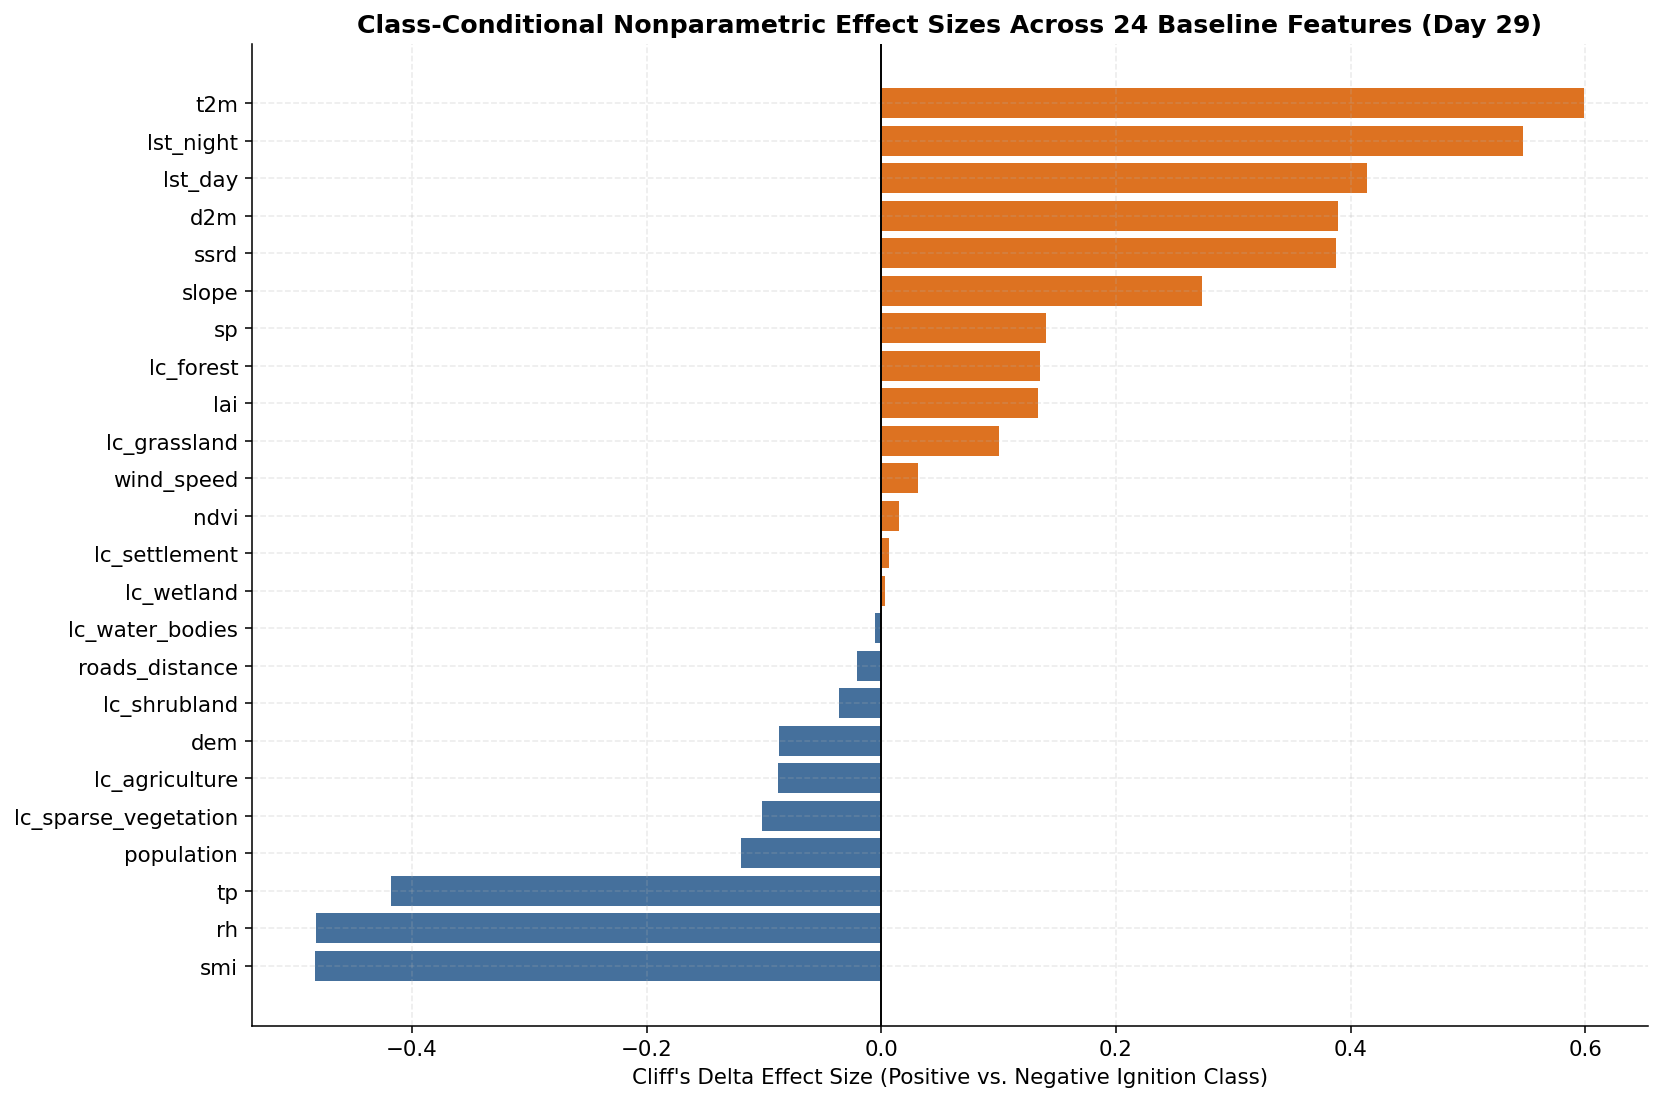

In [10]:
def cliffs_delta(x, y):
    u_stat, p_val = stats.mannwhitneyu(x, y, alternative="two-sided")
    delta = (2.0 * u_stat) / (len(x) * len(y)) - 1.0
    return delta, p_val


effect_rows = []
for feat in all_features:
    pos_v = train_d29.loc[train_d29["label"] == 1, feat].dropna().to_numpy()
    neg_v = train_d29.loc[train_d29["label"] == 0, feat].dropna().to_numpy()
    delta, p_val = cliffs_delta(pos_v, neg_v)
    effect_rows.append({
        "Feature": feat,
        "Type": "Dynamic" if feat in config["dynamic_features"] else "Static",
        "Pos Mean": pos_v.mean(),
        "Neg Mean": neg_v.mean(),
        "Cliffs_Delta": delta,
        "Abs_Delta": abs(delta),
        "p_value": p_val,
    })

effect_df = pd.DataFrame(effect_rows).sort_values("Cliffs_Delta", ascending=True)
n_tests = len(effect_df)
ranks = stats.rankdata(effect_df["p_value"])
effect_df["FDR_q"] = np.minimum(1.0, effect_df["p_value"] * n_tests / ranks)
display(effect_df.sort_values("Abs_Delta", ascending=False).head(12).round(5))

fig, ax = plt.subplots(figsize=(12, 8))
bar_colors = ["#d95f02" if d > 0 else "#2b5c8f" for d in effect_df["Cliffs_Delta"]]
ax.barh(effect_df["Feature"], effect_df["Cliffs_Delta"], color=bar_colors, alpha=0.88)
ax.axvline(0.0, color="black", linewidth=1.0)
ax.set_xlabel("Cliff's Delta Effect Size (Positive vs. Negative Ignition Class)")
ax.set_title("Class-Conditional Nonparametric Effect Sizes Across 24 Baseline Features (Day 29)")
plt.tight_layout()
plt.show()

## 3.6 Pre-Ignition 30-Day Temporal Trajectories

We visualize the 30-day temporal evolution (`mean +/- 95% CI`) from `time_idx = 0` to `29` across core meteorological and surface variables, marking the boundary (`28.5`) between the 29-day hindcast LSTM and final-day forecast LSTM.

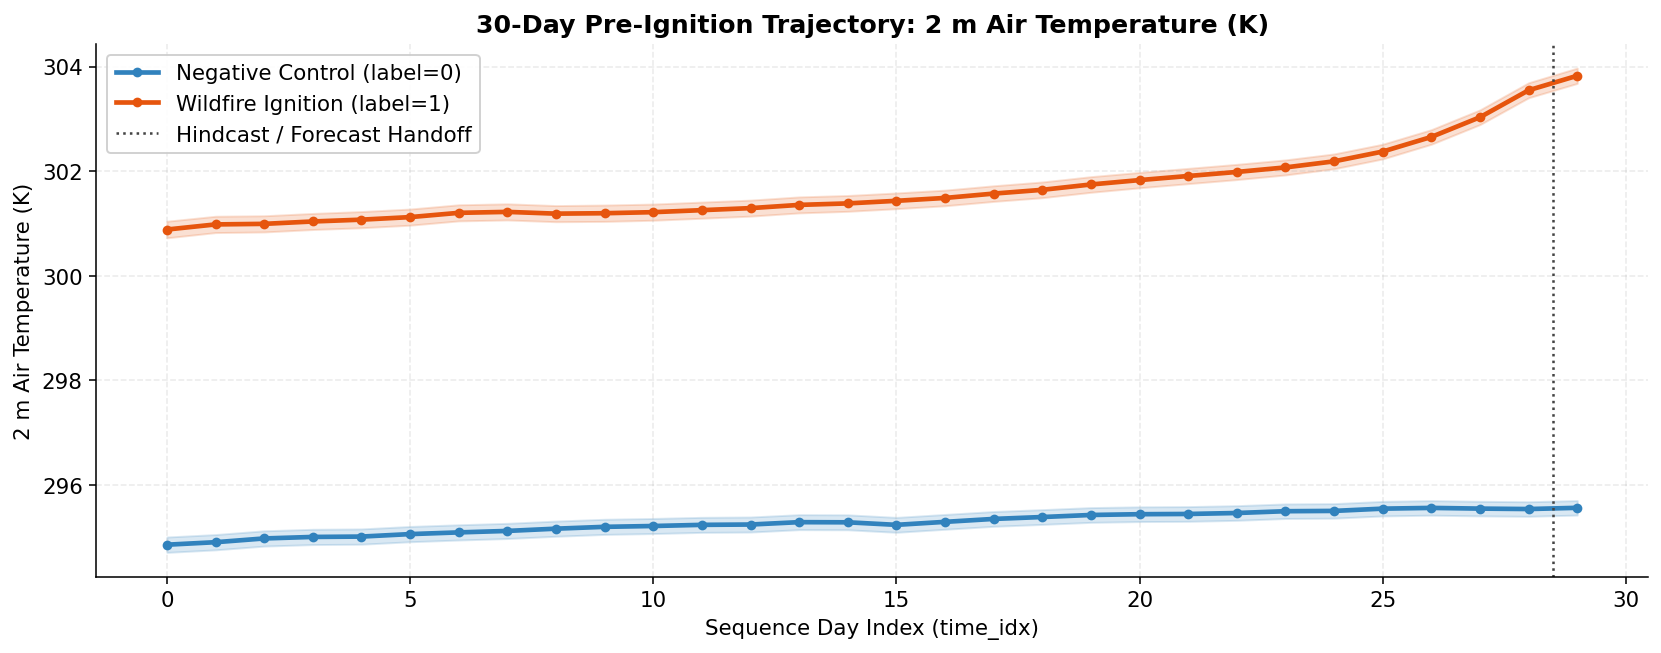

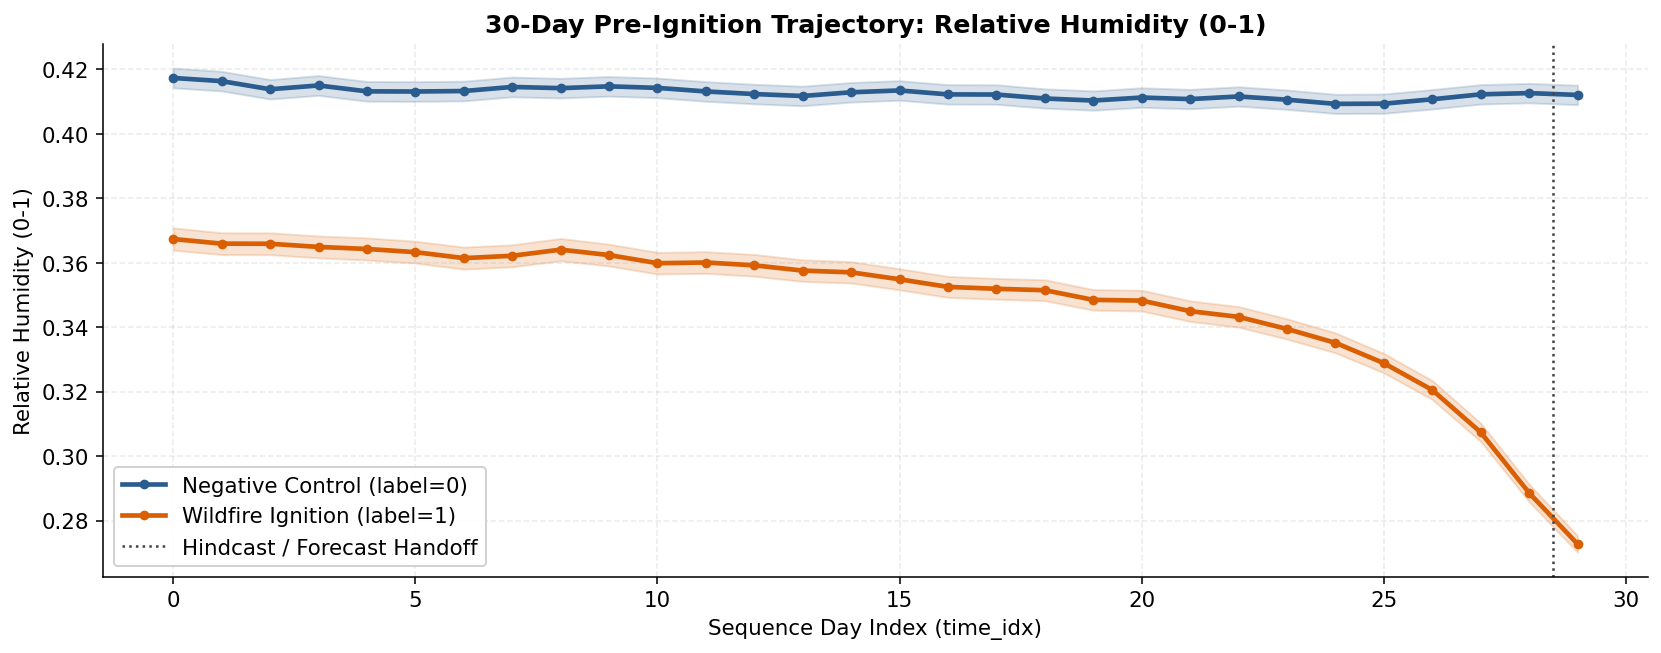

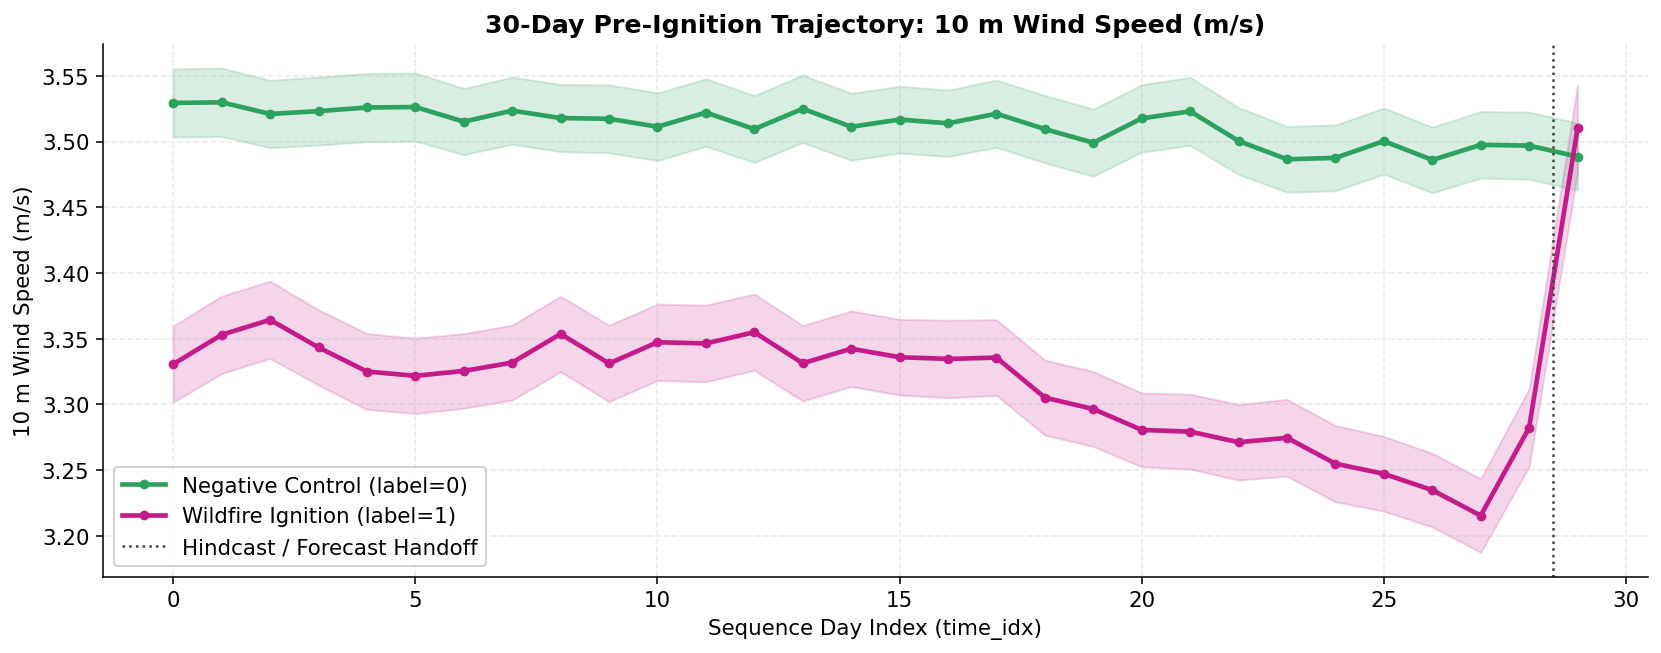

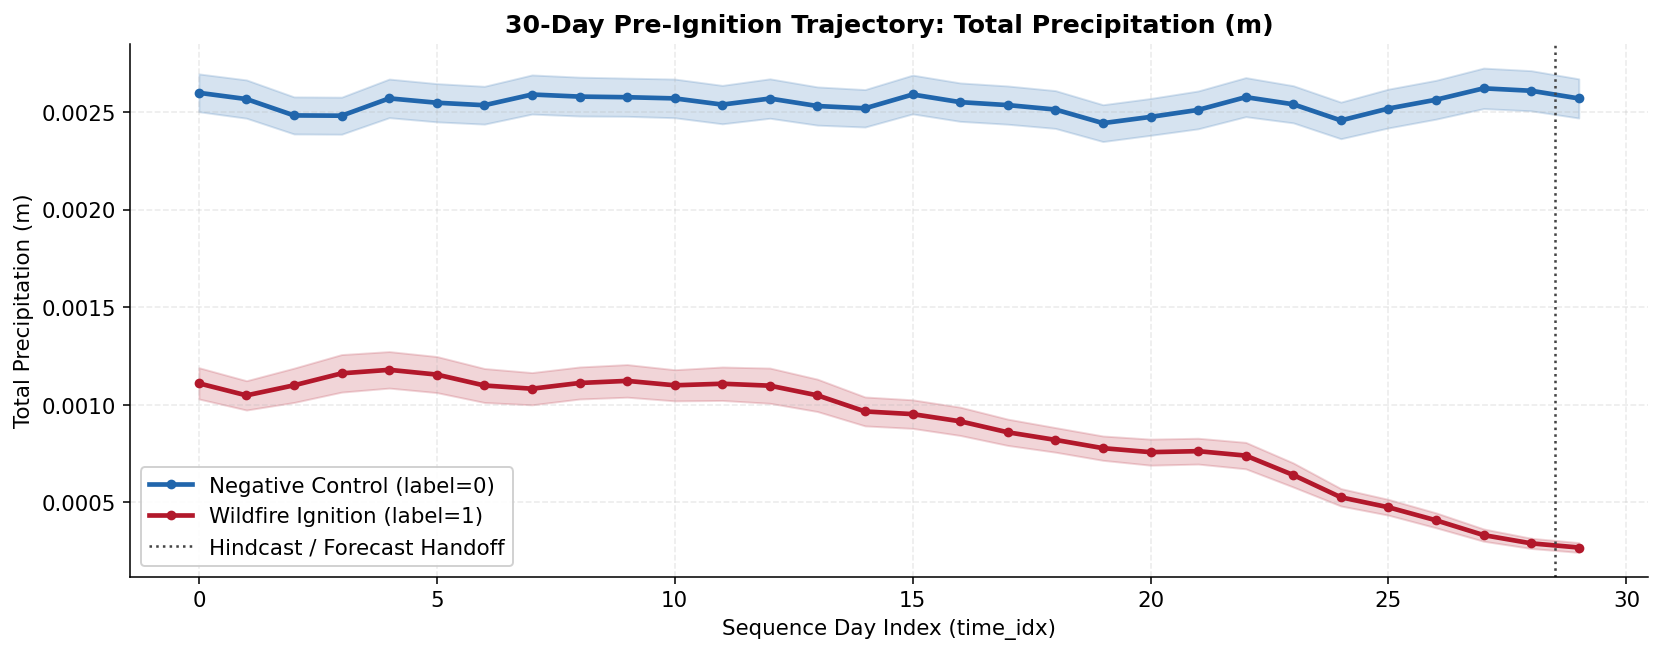

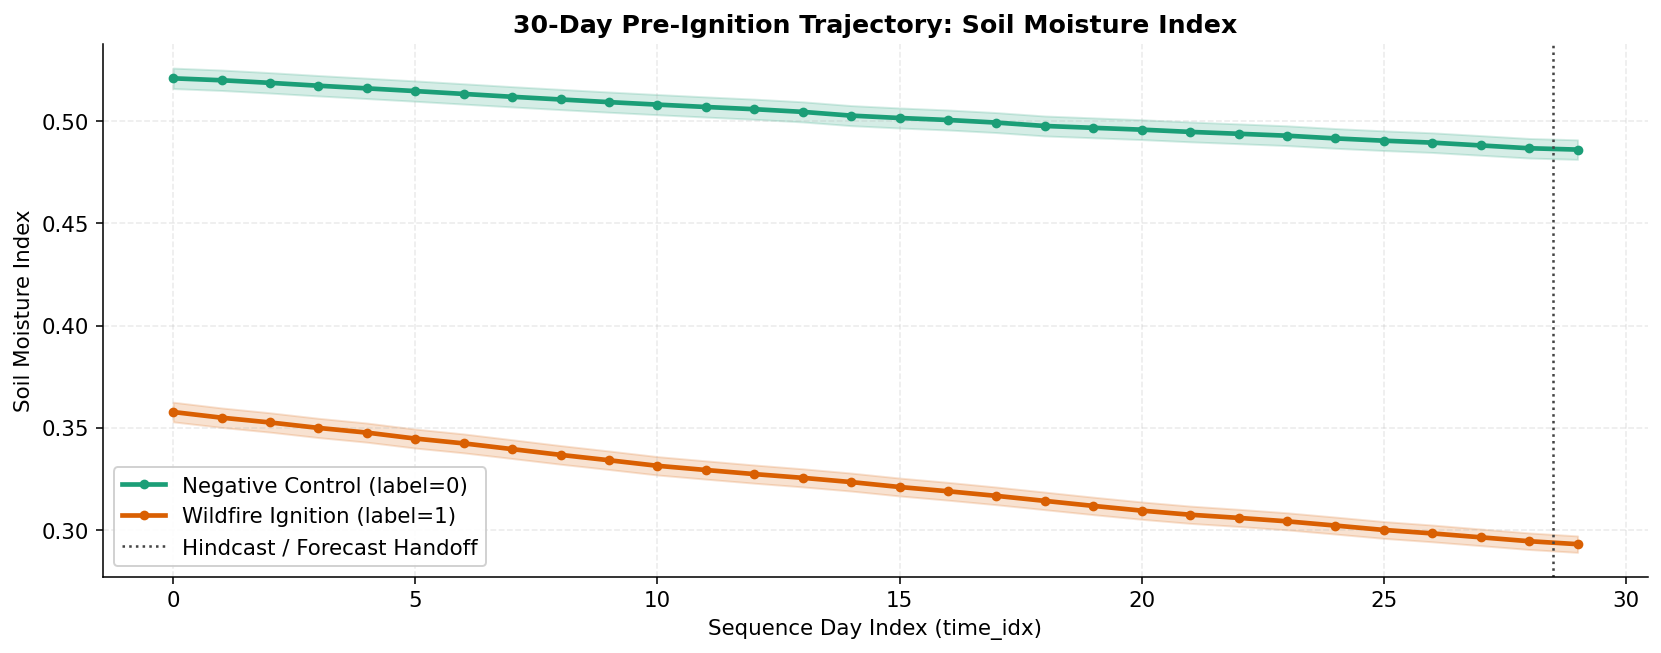

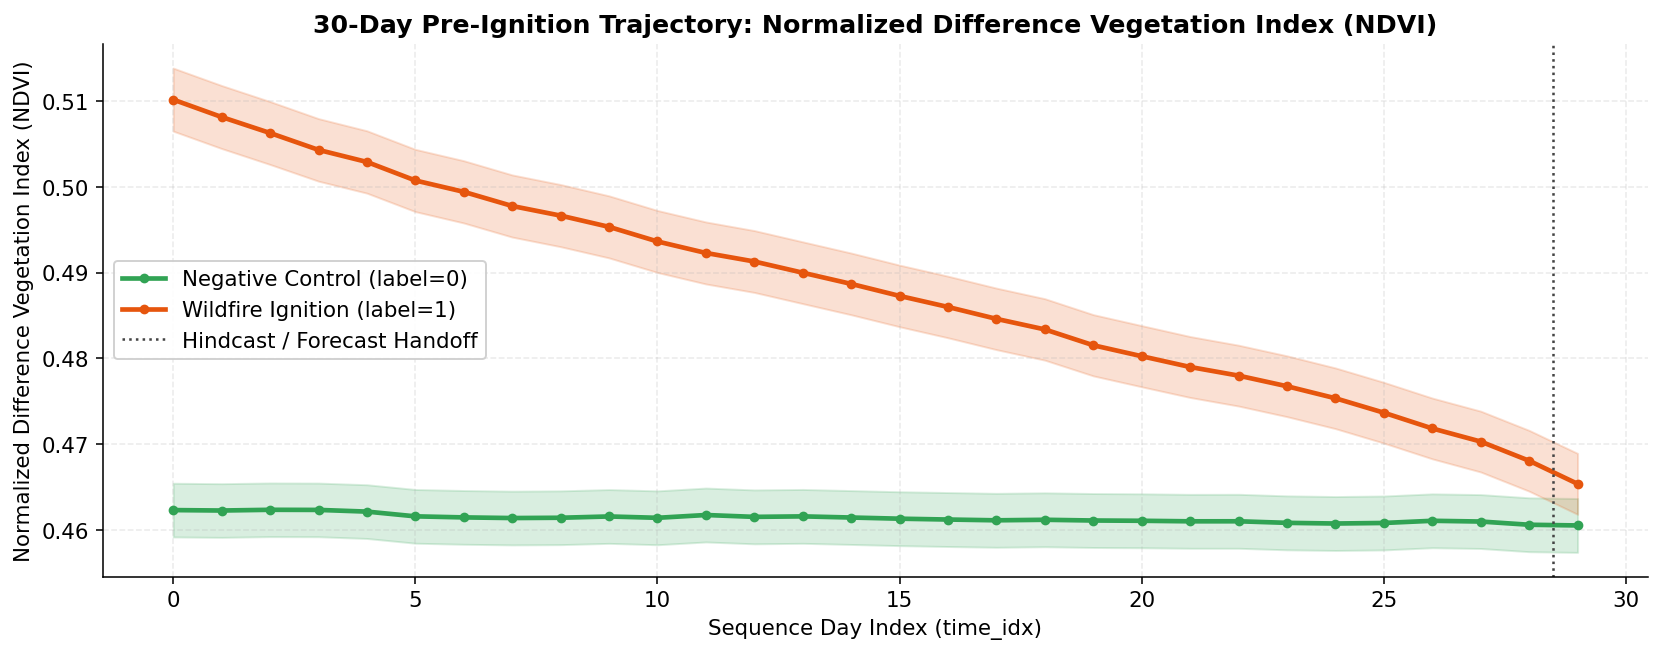

In [11]:
trajectory_vars = [
    ("t2m", "2 m Air Temperature (K)", "#e6550d", "#3182bd"),
    ("rh", "Relative Humidity (0-1)", "#d95f02", "#2b5c8f"),
    ("wind_speed", "10 m Wind Speed (m/s)", "#c51b8a", "#2ca25f"),
    ("tp", "Total Precipitation (m)", "#b2182b", "#2166ac"),
    ("smi", "Soil Moisture Index", "#d95f02", "#1b9e77"),
    ("ndvi", "Normalized Difference Vegetation Index (NDVI)", "#e6550d", "#31a354"),
]

for col, ylabel, c_pos, c_neg in trajectory_vars:
    grp = train_merged.groupby(["time_idx", "label"])[col].agg(["mean", "std", "count"]).reset_index()
    grp["ci95"] = 1.96 * grp["std"] / np.sqrt(grp["count"].clip(lower=1))

    fig, ax = plt.subplots(figsize=(12, 4.8))
    for lbl, color, label_txt in [(0, c_neg, "Negative Control (label=0)"), (1, c_pos, "Wildfire Ignition (label=1)")]:
        sub = grp[grp["label"] == lbl].sort_values("time_idx")
        ax.plot(sub["time_idx"], sub["mean"], color=color, linewidth=2.4, marker="o", markersize=4, label=label_txt)
        ax.fill_between(sub["time_idx"], sub["mean"] - sub["ci95"], sub["mean"] + sub["ci95"], color=color, alpha=0.18)
    ax.axvline(28.5, color="#444444", linestyle=":", linewidth=1.3, label="Hindcast / Forecast Handoff")
    ax.set_xlabel("Sequence Day Index (time_idx)")
    ax.set_ylabel(ylabel)
    ax.set_title(f"30-Day Pre-Ignition Trajectory: {ylabel}")
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()

## 3.7 Correlation and Mutual Information Structure

We inspect Spearman rank correlations across all 24 baseline predictors and the target label, followed by Mutual Information $I(X_j; Y)$ at `time_idx = 29`.

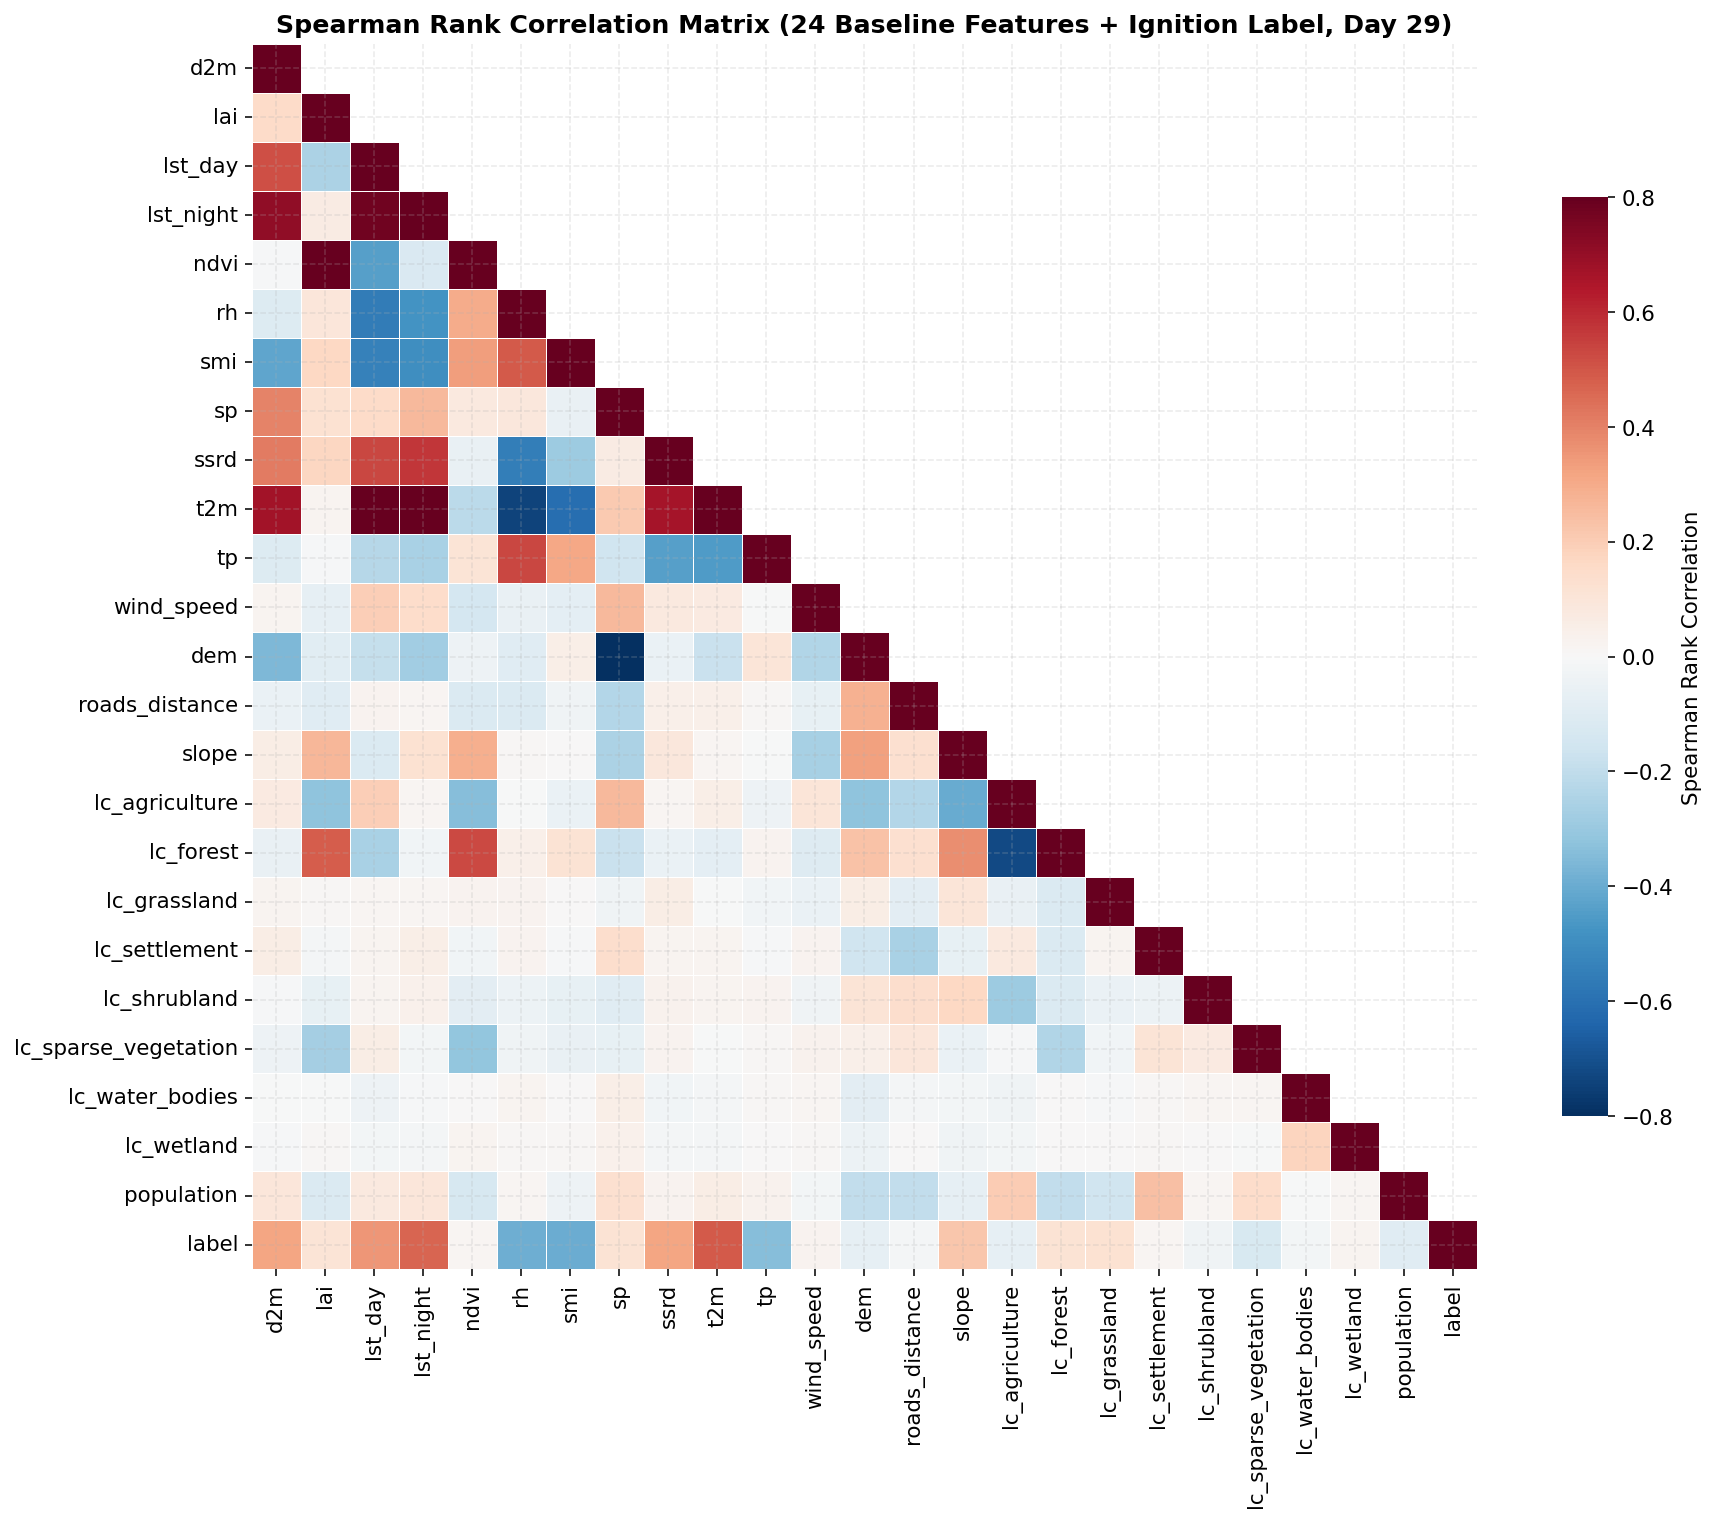

In [12]:
corr_cols = config["dynamic_features"] + config["static_features"] + ["label"]
spearman_corr = train_d29[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(spearman_corr, dtype=bool), k=1)
sns.heatmap(
    spearman_corr,
    mask=mask,
    cmap="RdBu_r",
    center=0.0,
    vmin=-0.8,
    vmax=0.8,
    square=True,
    linewidths=0.4,
    cbar_kws={"shrink": 0.75, "label": "Spearman Rank Correlation"},
    ax=ax,
)
ax.set_title("Spearman Rank Correlation Matrix (24 Baseline Features + Ignition Label, Day 29)")
plt.tight_layout()
plt.show()

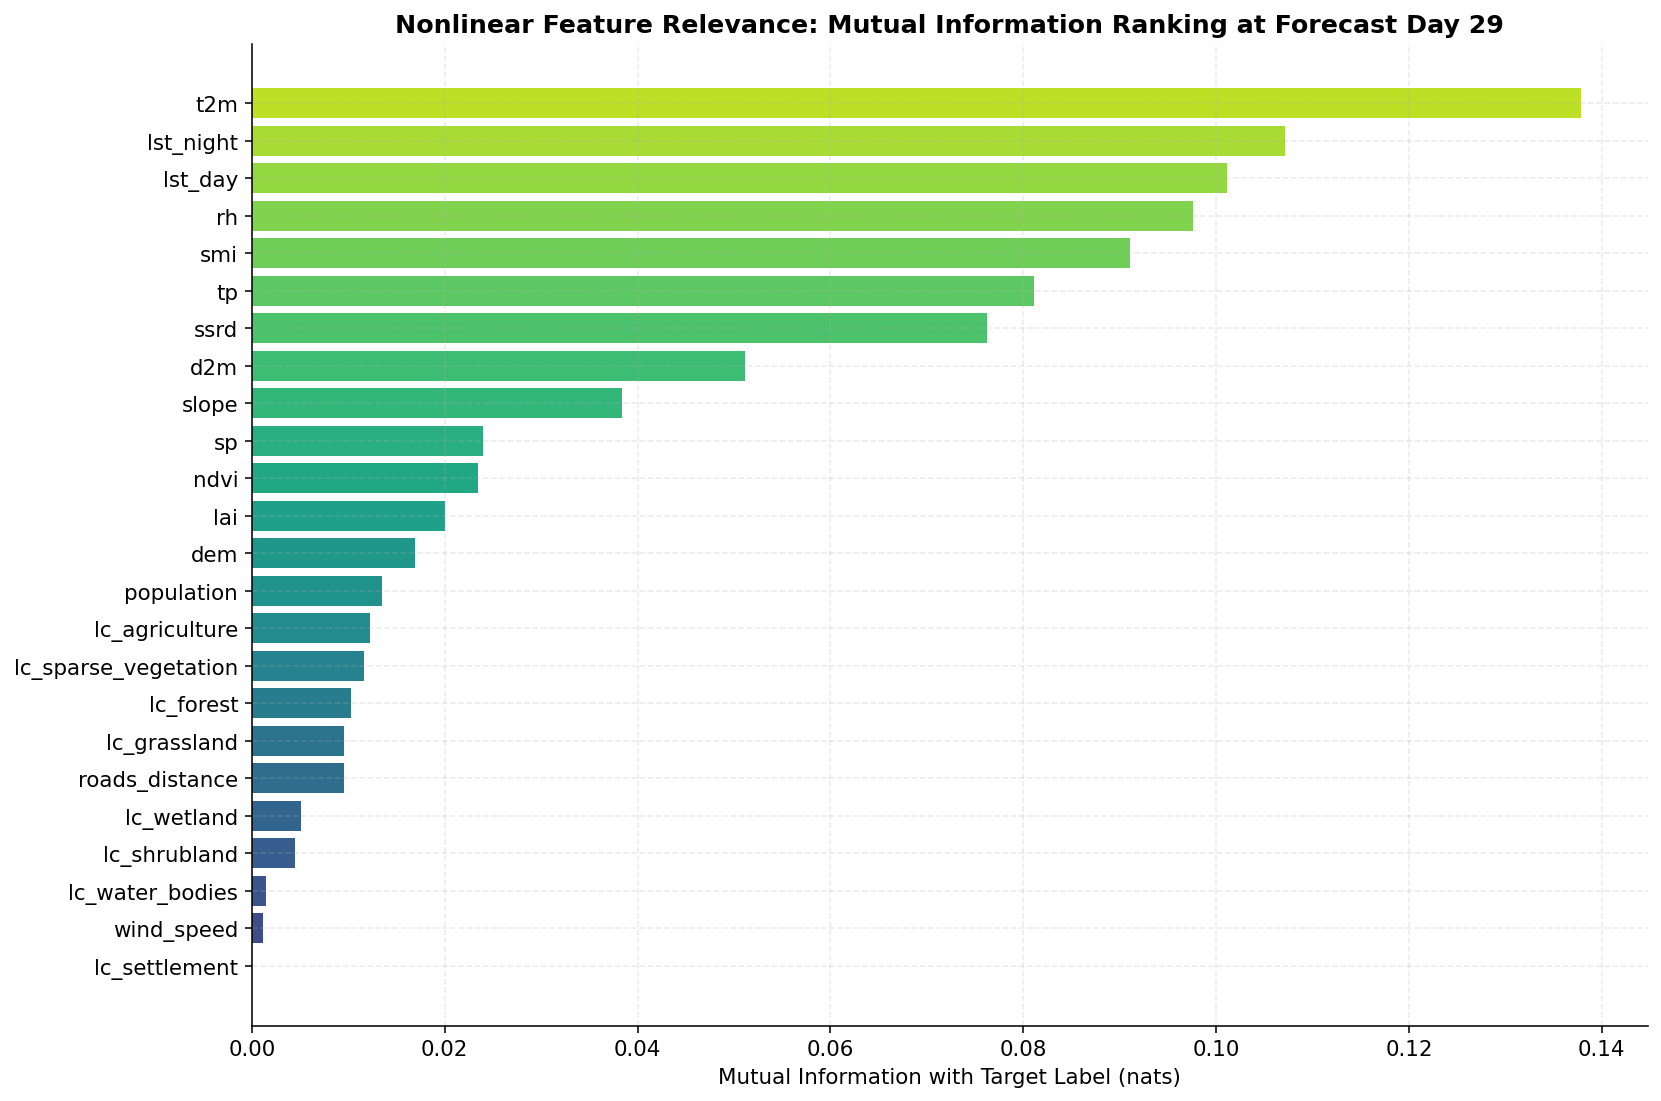

In [13]:
mi_X = train_d29[all_features].fillna(train_d29[all_features].median())
mi_y = train_d29["label"].to_numpy()
mi_scores = mutual_info_classif(mi_X, mi_y, random_state=SEED)
mi_df = pd.DataFrame({"Feature": all_features, "MI": mi_scores}).sort_values("MI", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
colors_mi = plt.cm.viridis(np.linspace(0.2, 0.9, len(mi_df)))
ax.barh(mi_df["Feature"], mi_df["MI"], color=colors_mi)
ax.set_xlabel("Mutual Information with Target Label (nats)")
ax.set_title("Nonlinear Feature Relevance: Mutual Information Ranking at Forecast Day 29")
plt.tight_layout()
plt.show()

## 3.8 Three-Dimensional Fire-Weather and Spatiotemporal Risk Manifolds

The 3D scatter plots below visualize coupled interactions among temperature, humidity, and wind speed, as well as the spatiotemporal structure excluded from the baseline feature vector.

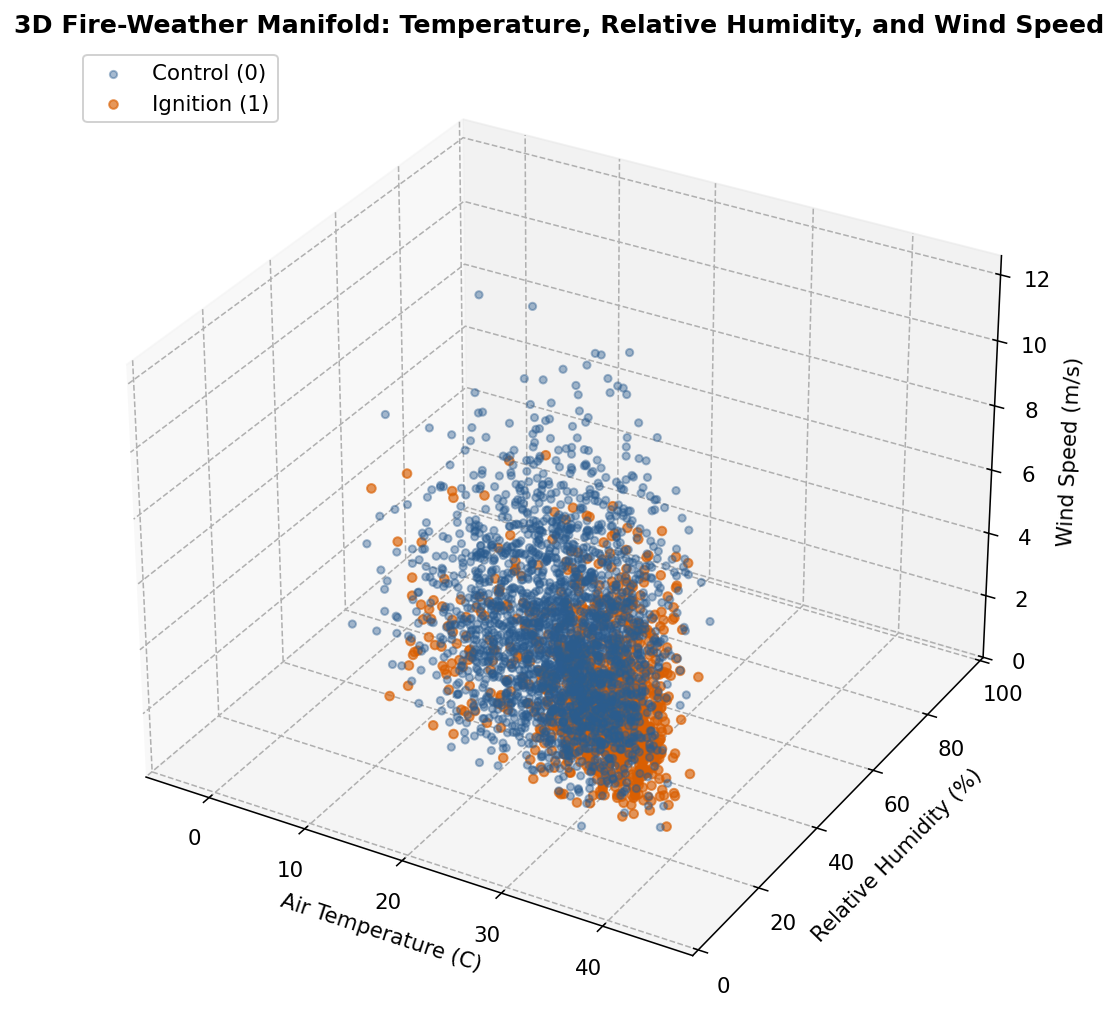

In [14]:
sample_3d = train_d29.sample(n=min(3500, len(train_d29)), random_state=SEED).copy()
sample_3d["t2m_c"] = sample_3d["t2m"] - 273.15

fig = plt.figure(figsize=(12, 7.5))
ax = fig.add_subplot(111, projection="3d")
for lbl, name_lbl in [(0, "Control (0)"), (1, "Ignition (1)")]:
    sub = sample_3d[sample_3d["label"] == lbl]
    ax.scatter(
        sub["t2m_c"],
        sub["rh"] * 100.0,
        sub["wind_speed"],
        c=PALETTE_CLASS[lbl],
        alpha=0.42 if lbl == 0 else 0.65,
        s=14 if lbl == 0 else 20,
        label=name_lbl,
    )
ax.set_xlabel("Air Temperature (C)")
ax.set_ylabel("Relative Humidity (%)")
ax.set_zlabel("Wind Speed (m/s)")
ax.set_title("3D Fire-Weather Manifold: Temperature, Relative Humidity, and Wind Speed")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

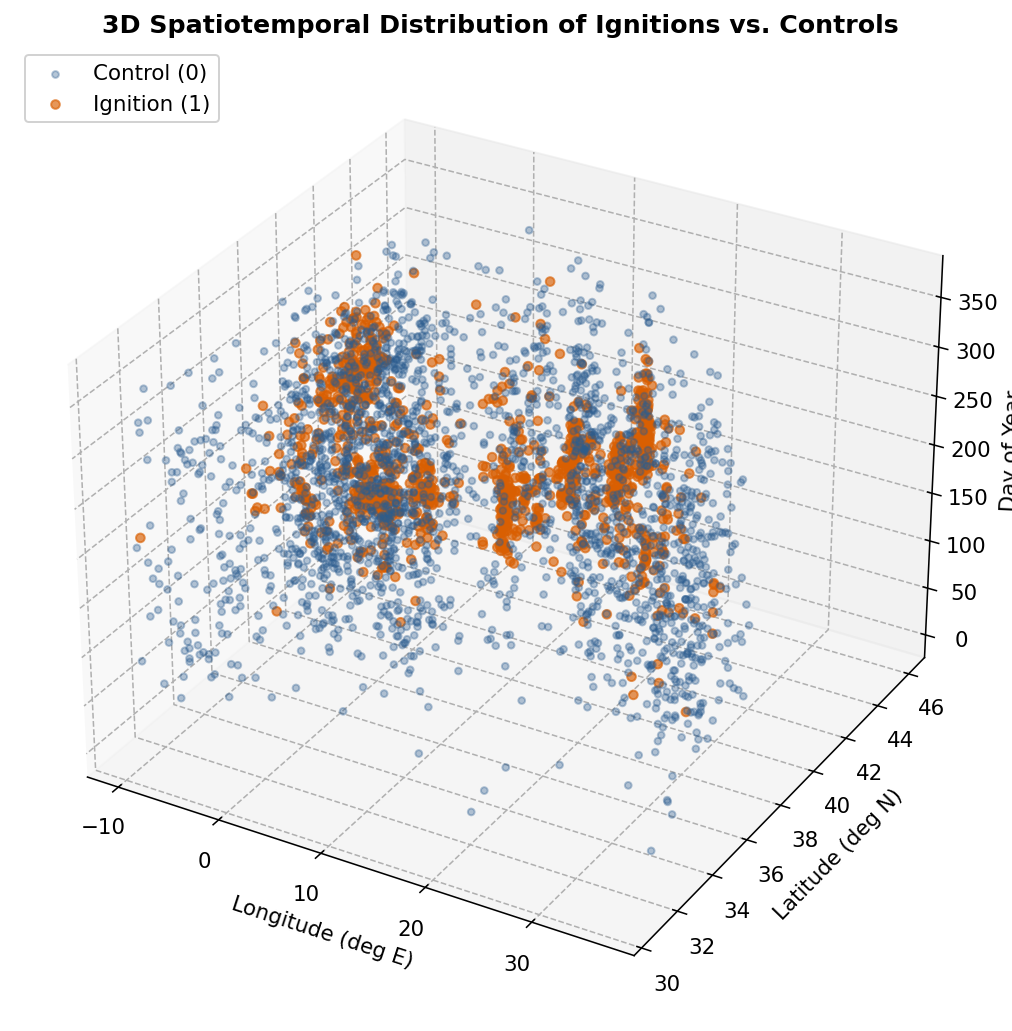

In [15]:
fig = plt.figure(figsize=(12, 7.5))
ax = fig.add_subplot(111, projection="3d")
for lbl, name_lbl in [(0, "Control (0)"), (1, "Ignition (1)")]:
    sub = sample_3d[sample_3d["label"] == lbl]
    ax.scatter(
        sub["longitude"],
        sub["latitude"],
        sub["doy"],
        c=PALETTE_CLASS[lbl],
        alpha=0.35 if lbl == 0 else 0.65,
        s=12 if lbl == 0 else 20,
        label=name_lbl,
    )
ax.set_xlabel("Longitude (deg E)")
ax.set_ylabel("Latitude (deg N)")
ax.set_zlabel("Day of Year")
ax.set_title("3D Spatiotemporal Distribution of Ignitions vs. Controls")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 4. Verification of the 24-Variable Control Baseline

The supplied `HandoffLSTM` processes `time_idx = 0..28` through a 128-unit hindcast LSTM, maps the terminal hidden and cell states $(h_{28}, c_{28})$ via a two-layer linear handoff network to $(h_0^{\mathrm{fc}}, c_0^{\mathrm{fc}})$, and advances one step on `time_idx = 29` (excluding satellite-derived `lai`, `lst_day`, `lst_night`, `ndvi`, `smi`) before a 3-layer MLP classification head. We evaluate the official checkpoint `clean_control_seed12345_state_dict.pt` on the validation set to establish our reference benchmark.

In [16]:
from dataset import MesogeosSequenceDataset
from extra_feature import ExtraFeatureDataset
from model_factory import build_model
from train_with_extra import prepare_input, weighted_original_loss
from torch.utils.data import DataLoader

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

control_summary = json.loads((BASELINE / "checkpoints" / "training_summary.json").read_text())
control_history = pd.read_csv(BASELINE / "checkpoints" / "training_history.csv")
print("Official Control Summary:", json.dumps(control_summary, indent=2))

val_base_ds = MesogeosSequenceDataset(
    sequences_path=DATA / "validation_sequences.csv",
    labels_path=DATA / "validation_labels.csv",
    dynamic_features=config["dynamic_features"],
    static_features=config["static_features"],
    sequence_length=config["sequence_length"],
)

val_loader_ctrl = DataLoader(val_base_ds, batch_size=config["training"]["batch_size"], shuffle=False, num_workers=0)
ctrl_model = build_model(config, extra_mode="none").to(DEVICE)
ctrl_ckpt = torch.load(BASELINE / "checkpoints" / "clean_control_seed12345_state_dict.pt", map_location=DEVICE, weights_only=True)
ctrl_model.load_state_dict(ctrl_ckpt, strict=True)
ctrl_model.eval()

ctrl_labels, ctrl_probs, ctrl_losses = [], [], []
with torch.no_grad():
    for dyn, stat, lw, lbl, _sid in val_loader_ctrl:
        x = prepare_input(dyn, stat, DEVICE)
        lbl_dev = lbl.to(DEVICE, dtype=torch.long)
        lw_dev = lw.to(DEVICE, dtype=torch.float32)
        logits = ctrl_model(x)
        loss_b, probs_b = weighted_original_loss(logits, lbl_dev, lw_dev)
        ctrl_labels.append(lbl.numpy())
        ctrl_probs.append(probs_b[:, 1].cpu().numpy())
        ctrl_losses.append(loss_b.item() * len(lbl))

ctrl_y = np.concatenate(ctrl_labels)
ctrl_p = np.concatenate(ctrl_probs)
ctrl_val_loss = sum(ctrl_losses) / len(ctrl_y)
ctrl_val_auprc = average_precision_score(ctrl_y, ctrl_p)
ctrl_val_roc = roc_auc_score(ctrl_y, ctrl_p)

print(f"Verified Control Validation Loss:  {ctrl_val_loss:.8f}")
print(f"Verified Control Validation AUPRC: {ctrl_val_auprc:.8f}")
print(f"Verified Control Validation ROC:   {ctrl_val_roc:.8f}")

Official Control Summary: {
  "seed": 12345,
  "best_epoch": 27,
  "best_validation_loss": 1.1490526357443327,
  "best_validation_auprc": 0.9019664522912331,
  "checkpoint": "checkpoints/clean_control_seed12345_state_dict.pt"
}
Verified Control Validation Loss:  1.14905241
Verified Control Validation AUPRC: 0.90196645
Verified Control Validation ROC:   0.94472451


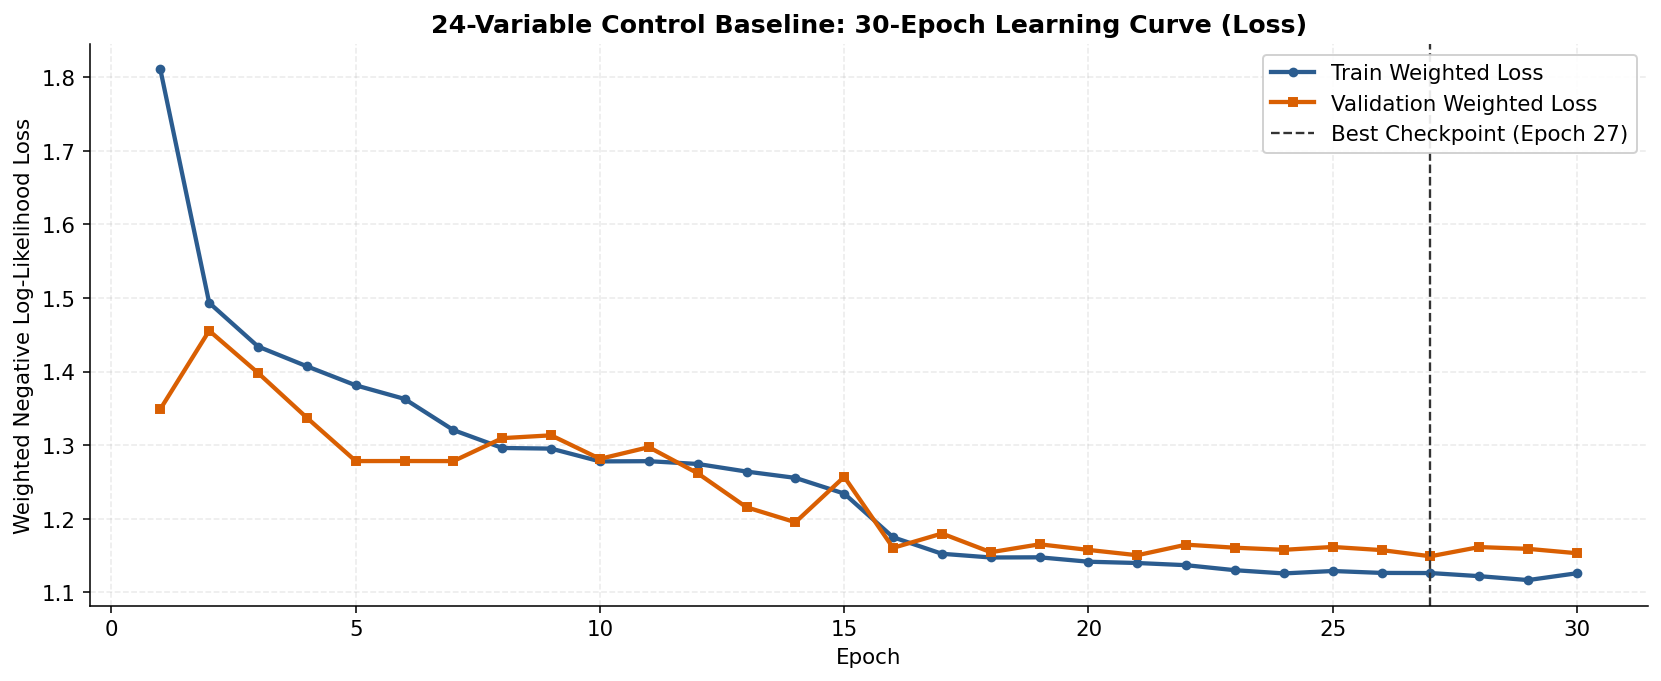

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(control_history["epoch"], control_history["train_loss"], color="#2b5c8f", linewidth=2.2, marker="o", markersize=4, label="Train Weighted Loss")
ax.plot(control_history["epoch"], control_history["validation_loss"], color="#d95f02", linewidth=2.2, marker="s", markersize=4, label="Validation Weighted Loss")
best_ep = int(control_summary["best_epoch"])
ax.axvline(best_ep, color="#333333", linestyle="--", linewidth=1.2, label=f"Best Checkpoint (Epoch {best_ep})")
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted Negative Log-Likelihood Loss")
ax.set_title("24-Variable Control Baseline: 30-Epoch Learning Curve (Loss)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

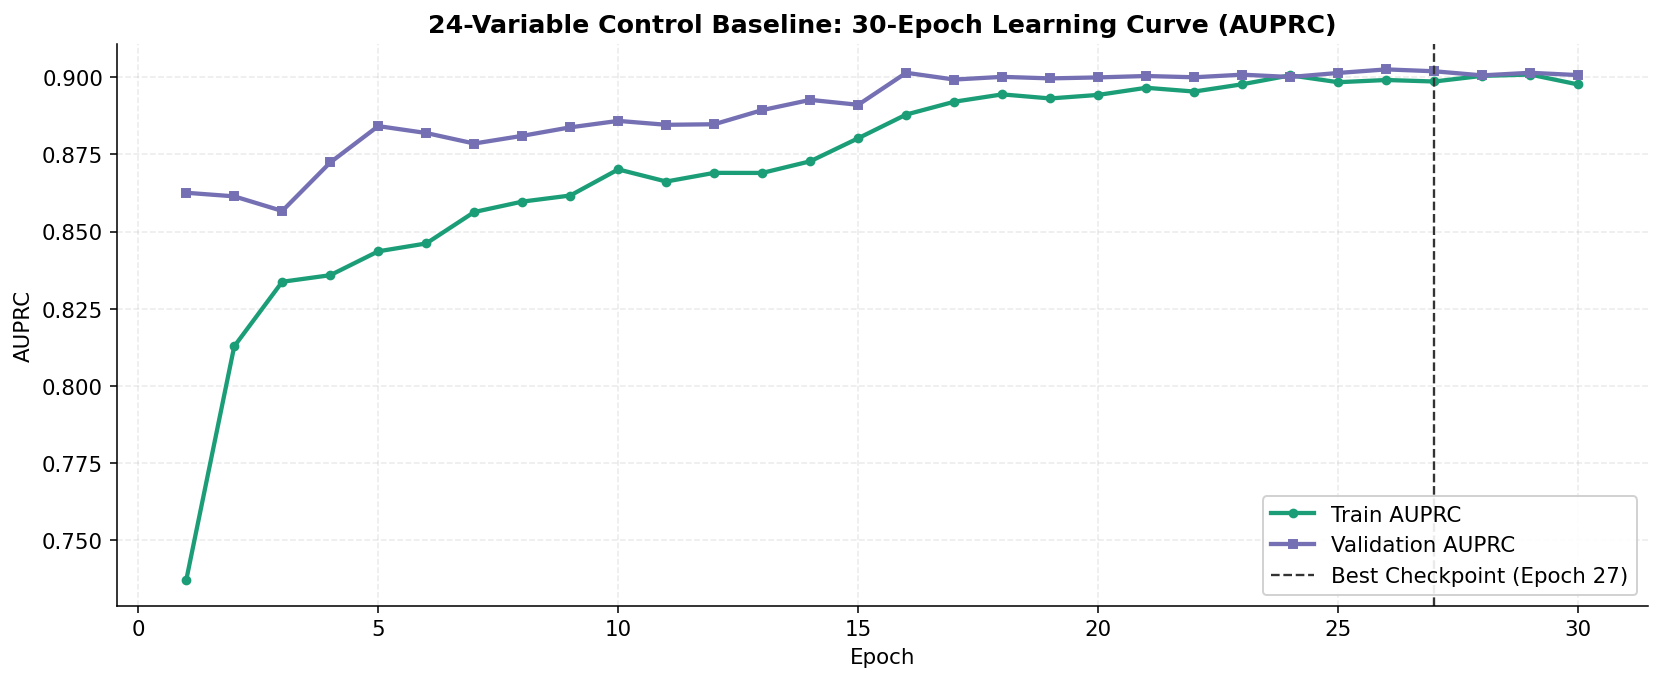

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(control_history["epoch"], control_history["train_auprc"], color="#1b9e77", linewidth=2.2, marker="o", markersize=4, label="Train AUPRC")
ax.plot(control_history["epoch"], control_history["validation_auprc"], color="#7570b3", linewidth=2.2, marker="s", markersize=4, label="Validation AUPRC")
ax.axvline(best_ep, color="#333333", linestyle="--", linewidth=1.2, label=f"Best Checkpoint (Epoch {best_ep})")
ax.set_xlabel("Epoch")
ax.set_ylabel("AUPRC")
ax.set_title("24-Variable Control Baseline: 30-Epoch Learning Curve (AUPRC)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 5. External Modality Acquisition: NASA POWER (MERRA-2) Reanalysis

Per the competition rules (FAQ #9, #10, #11, #13), the additional predictor must originate from a **legitimate external data source** rather than a recombination of the 24 supplied baseline variables or direct calendar/coordinate encodings. We retrieve four physically distinct daily variables from the public, keyless **NASA POWER (Prediction Of Worldwide Energy Resources) MERRA-2 Agroclimatology Regional API** (`https://power.larc.nasa.gov/api/temporal/daily/regional`):

1. **`GWETTOP`** (dimensionless, $0\text{–}1$): Surface soil wetness (0–5 cm depth) from MERRA-2 land-surface assimilation. Provides gap-free topsoil moisture where MESOGEOS satellite `smi` has `15.58%` missingness in training.
2. **`GWETROOT`** (dimensionless, $0\text{–}1$): Root-zone soil wetness (0–100 cm depth). Captures deeper multi-week hydrological drought memory governing live-fuel moisture stress.
3. **`WS10M_MAX`** ($\mathrm{m\,s^{-1}}$): Daily maximum 10 m wind speed. MESOGEOS supplies only daily mean `wind_speed`; peak wind gusts govern convective spotting and rapid spread.
4. **`T2M_RANGE`** ($^\circ\mathrm{C}$): Daily diurnal 2 m air-temperature range ($T_{\max} - T_{\min}$), capturing afternoon thermal extremes and radiative boundary-layer destabilization not visible in daily mean `t2m`.

## Spatial & Temporal Alignment Protocol
- **Spatial Alignment**: The Mediterranean domain ($\lambda \in [-10.0^\circ, 36.5^\circ]$, $\phi \in [30.5^\circ, 46.0^\circ]$) is tiled into $10$ regional bounding boxes ($10^\circ \times 10^\circ$) on MERRA-2's native $0.5^\circ \times 0.625^\circ$ grid. Each sample coordinate $(\lambda_i, \phi_i)$ is matched deterministically to its nearest MERRA-2 grid node via Euclidean `cKDTree`.
- **Temporal Alignment**: Daily UTC fields (`2006-04-01` to `2022-09-29`) are joined by exact `(grid_lat, grid_lon, time)` keys across all 30 sequence days (`time_idx = 0..29`, `dynamic_forecast` mode).
- **Reproducibility & Caching**: Regional tiles are cached to `/kaggle/working/nasa_power_cache/`.

In [19]:
NASA_VARS = [
    "GWETTOP",
    "GWETROOT",
    "WS10M_MAX",
    "T2M_RANGE",
]

CANDIDATE_LABELS = {
    "GWETTOP": "NASA POWER Surface Soil Wetness 0-5cm (0-1)",
    "GWETROOT": "NASA POWER Root-Zone Soil Wetness 0-100cm (0-1)",
    "WS10M_MAX": "NASA POWER Daily Max 10m Wind Speed (m/s)",
    "T2M_RANGE": "NASA POWER Diurnal 2m Temp Range (C)",
}

CACHE_DIR = WORK / "nasa_power_cache"
TILE_CACHE_DIR = CACHE_DIR / "tiles"
TILE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_FILE = CACHE_DIR / "nasa_power_mediterranean.parquet"

# 10 tiles covering lon [-10, 36.5] and lat [30.5, 46.0]
LON_TILES = [(-10.0, -0.5), (0.0, 9.5), (10.0, 19.5), (20.0, 29.5), (30.0, 36.5)]
LAT_TILES = [(30.5, 38.0), (38.5, 46.0)]
ALL_YEARS = sorted(set(train_seq["time_dt"].dt.year).union(val_seq["time_dt"].dt.year).union(test_seq["time_dt"].dt.year))


def fetch_nasa_tile(param, yr, lon_min, lon_max, lat_min, lat_max):
    part_path = TILE_CACHE_DIR / f"{param}_y{yr}_lon{lon_min:.0f}_lat{lat_min:.0f}.parquet"
    if part_path.is_file():
        return pd.read_parquet(part_path)

    url = (
        f"https://power.larc.nasa.gov/api/temporal/daily/regional?"
        f"parameters={param}&community=AG"
        f"&longitude-min={lon_min}&longitude-max={lon_max}"
        f"&latitude-min={lat_min}&latitude-max={lat_max}"
        f"&start={yr}0101&end={yr}1231&format=JSON"
    )
    for attempt in range(8):
        try:
            resp = requests.get(url, timeout=60)
            if resp.status_code == 429:
                wait_s = min(float(resp.headers.get("Retry-After", 15.0 * (attempt + 1))), 65.0)
                time.sleep(wait_s)
                continue
            resp.raise_for_status()
            features = resp.json().get("features", [])
            rows = []
            for feat in features:
                glon, glat = feat["geometry"]["coordinates"][:2]
                vals_dict = feat["properties"]["parameter"][param]
                for d_str, val in vals_dict.items():
                    v = np.nan if val <= -900 else float(val)
                    rows.append((glat, glon, f"{d_str[:4]}-{d_str[4:6]}-{d_str[6:8]}", v))
            df_tile = pd.DataFrame(rows, columns=["grid_lat", "grid_lon", "time", param])
            df_tile[param] = df_tile[param].astype(np.float32)
            df_tile.to_parquet(part_path, index=False)
            time.sleep(0.15)
            return df_tile
        except Exception:
            if attempt == 7:
                raise
            time.sleep(5.0 * (attempt + 1))


if CACHE_FILE.is_file():
    print(f"Loading cached NASA POWER table from {CACHE_FILE}", flush=True)
    nasa_grid = pd.read_parquet(CACHE_FILE)
else:
    param_tables = []
    for param in NASA_VARS:
        tasks = [
            (yr, lo0, lo1, la0, la1)
            for yr in ALL_YEARS
            for (lo0, lo1) in LON_TILES
            for (la0, la1) in LAT_TILES
        ]
        print(f"Fetching {param}: {len(tasks)} regional tiles across {ALL_YEARS[0]}-{ALL_YEARS[-1]}...", flush=True)
        t0 = time.time()
        parts = []
        with ThreadPoolExecutor(max_workers=2) as pool:
            futs = [pool.submit(fetch_nasa_tile, param, *t) for t in tasks]
            for idx_f, fut in enumerate(as_completed(futs), start=1):
                parts.append(fut.result())
                if idx_f % 40 == 0 or idx_f == len(tasks):
                    print(f"  {param}: {idx_f}/{len(tasks)} tiles ({time.time() - t0:.1f}s)", flush=True)
        df_p = pd.concat(parts, ignore_index=True).drop_duplicates(subset=["grid_lat", "grid_lon", "time"])
        param_tables.append(df_p.set_index(["grid_lat", "grid_lon", "time"]))

    nasa_grid = pd.concat(param_tables, axis=1).reset_index()
    nasa_grid.to_parquet(CACHE_FILE, index=False)
    print(f"Saved NASA POWER cache to {CACHE_FILE} ({len(nasa_grid):,} rows)", flush=True)

Fetching GWETTOP: 170 regional tiles across 2006-2022...
  GWETTOP: 40/170 tiles (25.8s)
  GWETTOP: 80/170 tiles (52.3s)
  GWETTOP: 120/170 tiles (78.8s)
  GWETTOP: 160/170 tiles (104.7s)
  GWETTOP: 170/170 tiles (111.7s)
Fetching GWETROOT: 170 regional tiles across 2006-2022...
  GWETROOT: 40/170 tiles (27.0s)
  GWETROOT: 80/170 tiles (54.9s)
  GWETROOT: 120/170 tiles (79.7s)
  GWETROOT: 160/170 tiles (106.3s)
  GWETROOT: 170/170 tiles (112.7s)
Fetching WS10M_MAX: 170 regional tiles across 2006-2022...
  WS10M_MAX: 40/170 tiles (25.9s)
  WS10M_MAX: 80/170 tiles (52.4s)
  WS10M_MAX: 120/170 tiles (78.6s)
  WS10M_MAX: 160/170 tiles (106.6s)
  WS10M_MAX: 170/170 tiles (115.6s)
Fetching T2M_RANGE: 170 regional tiles across 2006-2022...
  T2M_RANGE: 40/170 tiles (27.3s)
  T2M_RANGE: 80/170 tiles (56.0s)
  T2M_RANGE: 120/170 tiles (82.4s)
  T2M_RANGE: 160/170 tiles (109.1s)
  T2M_RANGE: 170/170 tiles (115.4s)
Saved NASA POWER cache to /kaggle/working/nasa_power_cache/nasa_power_mediterranea

In [20]:
# Nearest-neighbor spatial alignment via cKDTree onto MERRA-2 grid nodes
grid_coords = nasa_grid[["grid_lat", "grid_lon"]].drop_duplicates().sort_values(["grid_lat", "grid_lon"]).reset_index(drop=True)
tree = cKDTree(grid_coords[["grid_lat", "grid_lon"]].to_numpy())

CAND_DIR = WORK / "candidates"
CAND_DIR.mkdir(parents=True, exist_ok=True)

split_aligned = {}
for split_tag, seq_df in [("train", train_seq), ("validation", val_seq), ("test", test_seq)]:
    _, nn_idx = tree.query(seq_df[["latitude", "longitude"]].to_numpy(), k=1)
    tmp_keys = pd.DataFrame({
        "competition_id": seq_df["competition_id"],
        "time_idx": seq_df["time_idx"],
        "time": seq_df["time"],
        "grid_lat": grid_coords["grid_lat"].to_numpy()[nn_idx],
        "grid_lon": grid_coords["grid_lon"].to_numpy()[nn_idx],
    })
    merged = tmp_keys.merge(nasa_grid, on=["grid_lat", "grid_lon", "time"], how="left", validate="many_to_one")
    assert len(merged) == len(seq_df), f"Alignment row mismatch in {split_tag}"
    split_aligned[split_tag] = merged
    miss_rates = merged[NASA_VARS].isna().mean() * 100.0
    print(f"{split_tag.capitalize()} NASA POWER missingness (%):", miss_rates.round(4).to_dict())

screening_rows = []
d29_mask = train_seq["time_idx"].to_numpy() == 29
d29_y = train_merged.loc[d29_mask, "label"].to_numpy()

for cname in NASA_VARS:
    c_path = CAND_DIR / cname
    c_path.mkdir(parents=True, exist_ok=True)
    for split_tag in ["train", "validation", "test"]:
        out_df = pd.DataFrame({
            "competition_id": split_aligned[split_tag]["competition_id"],
            "time_idx": split_aligned[split_tag]["time_idx"],
            "extra_feature": split_aligned[split_tag][cname].to_numpy(dtype=np.float32),
        })
        out_df.to_csv(c_path / f"{split_tag}_extra.csv", index=False)

    vals_d29 = split_aligned["train"].loc[d29_mask, cname].to_numpy()
    valid_m = np.isfinite(vals_d29)
    delta, _ = cliffs_delta(vals_d29[valid_m & (d29_y == 1)], vals_d29[valid_m & (d29_y == 0)])
    score_dir = -vals_d29[valid_m] if "GWET" in cname else vals_d29[valid_m]
    uni_auprc = average_precision_score(d29_y[valid_m], score_dir)
    screening_rows.append({
        "Candidate": cname,
        "Description": CANDIDATE_LABELS[cname],
        "Train Mean (D29)": float(np.nanmean(vals_d29)),
        "Train Std (D29)": float(np.nanstd(vals_d29)),
        "Cliffs_Delta (D29)": float(delta),
        "Univariate AUPRC (D29)": float(uni_auprc),
    })

screening_df = pd.DataFrame(screening_rows).sort_values("Univariate AUPRC (D29)", ascending=False)
display(screening_df.round(5))

Train NASA POWER missingness (%): {'GWETTOP': 0.0, 'GWETROOT': 0.0, 'WS10M_MAX': 0.0, 'T2M_RANGE': 0.0}
Validation NASA POWER missingness (%): {'GWETTOP': 0.0, 'GWETROOT': 0.0, 'WS10M_MAX': 0.0, 'T2M_RANGE': 0.0}
Test NASA POWER missingness (%): {'GWETTOP': 0.0, 'GWETROOT': 0.0, 'WS10M_MAX': 0.0, 'T2M_RANGE': 0.0}


,Candidate,Description,Train Mean (D29),Train Std (D29),Cliffs_Delta (D29),Univariate AUPRC (D29)
0,GWETTOP,NASA POWER Surface Soil Wetness 0-5cm (0-1),0.42491,0.18963,-0.48360,0.51617
3,T2M_RANGE,NASA POWER Diurnal 2m Temp Range (C),12.57588,4.14949,0.22893,0.44006
1,GWETROOT,NASA POWER Root-Zone Soil Wetness 0-100cm (0-1),0.49703,0.12441,-0.29340,0.43615
2,WS10M_MAX,NASA POWER Daily Max 10m Wind Speed (m/s),5.44529,2.06716,-0.09245,0.29555


## 5.1 Class-Conditional Densities of the External NASA POWER Predictors

We inspect the empirical class-conditional distributions of each retrieved MERRA-2 variable at `time_idx = 29` in the training split.

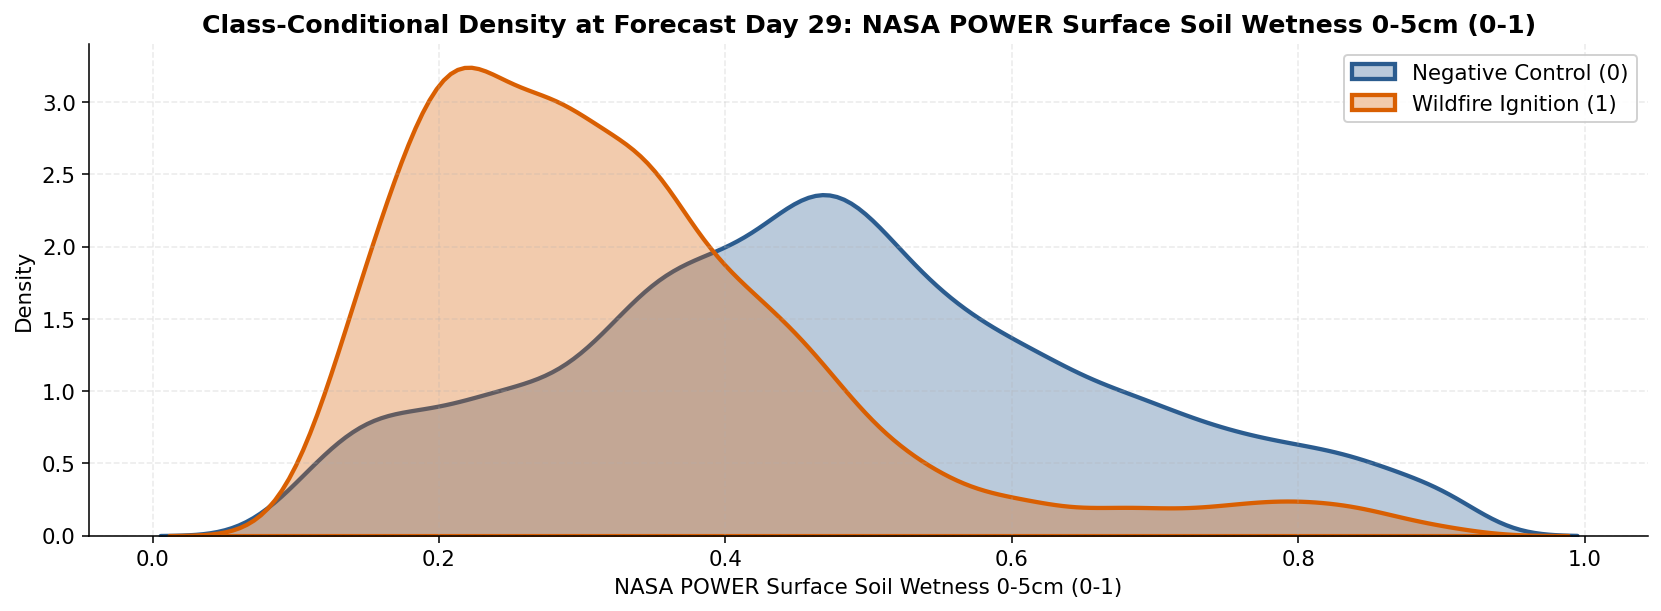

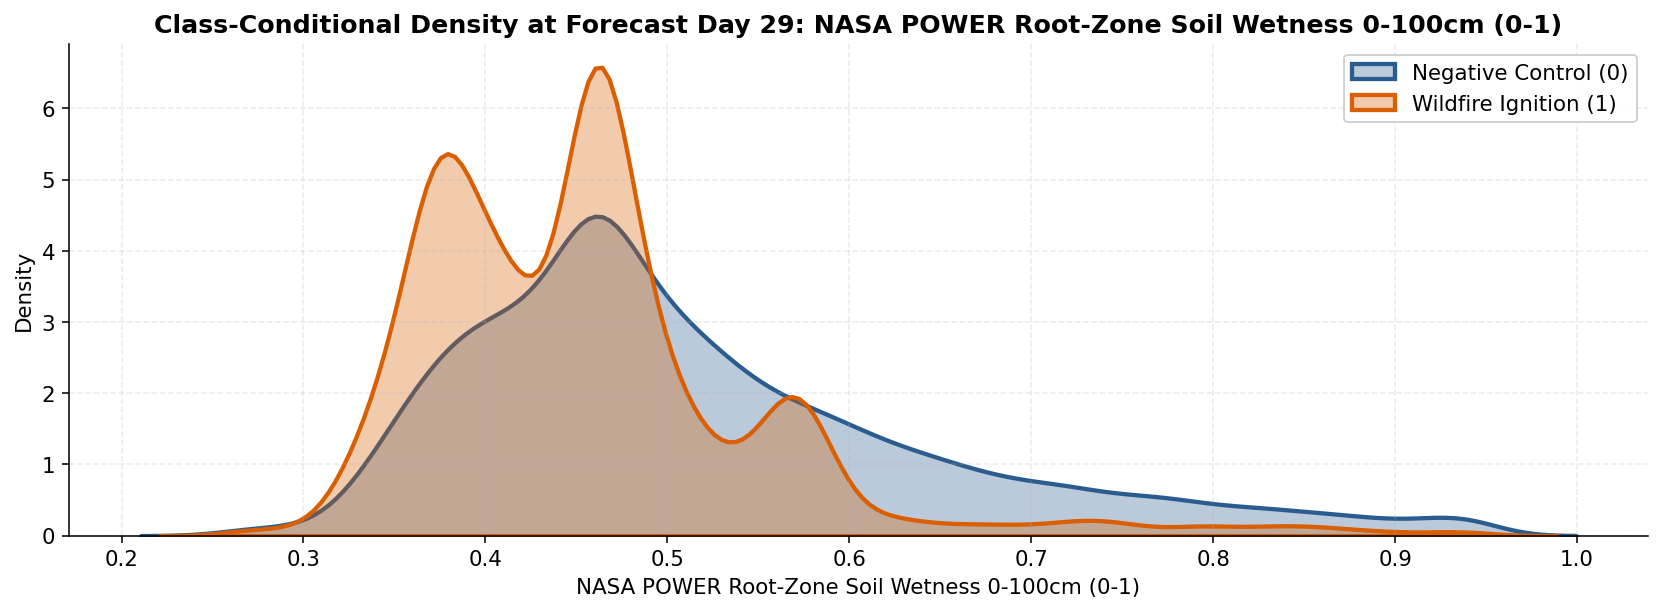

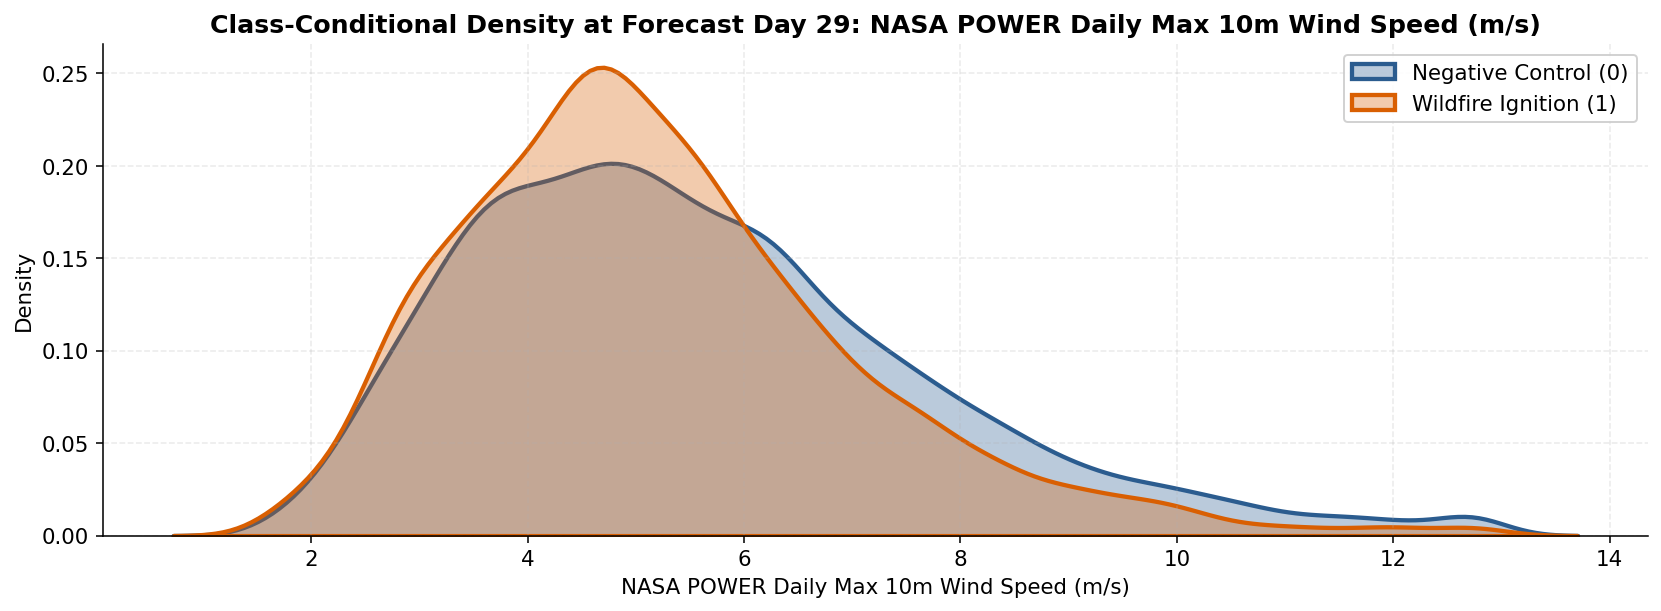

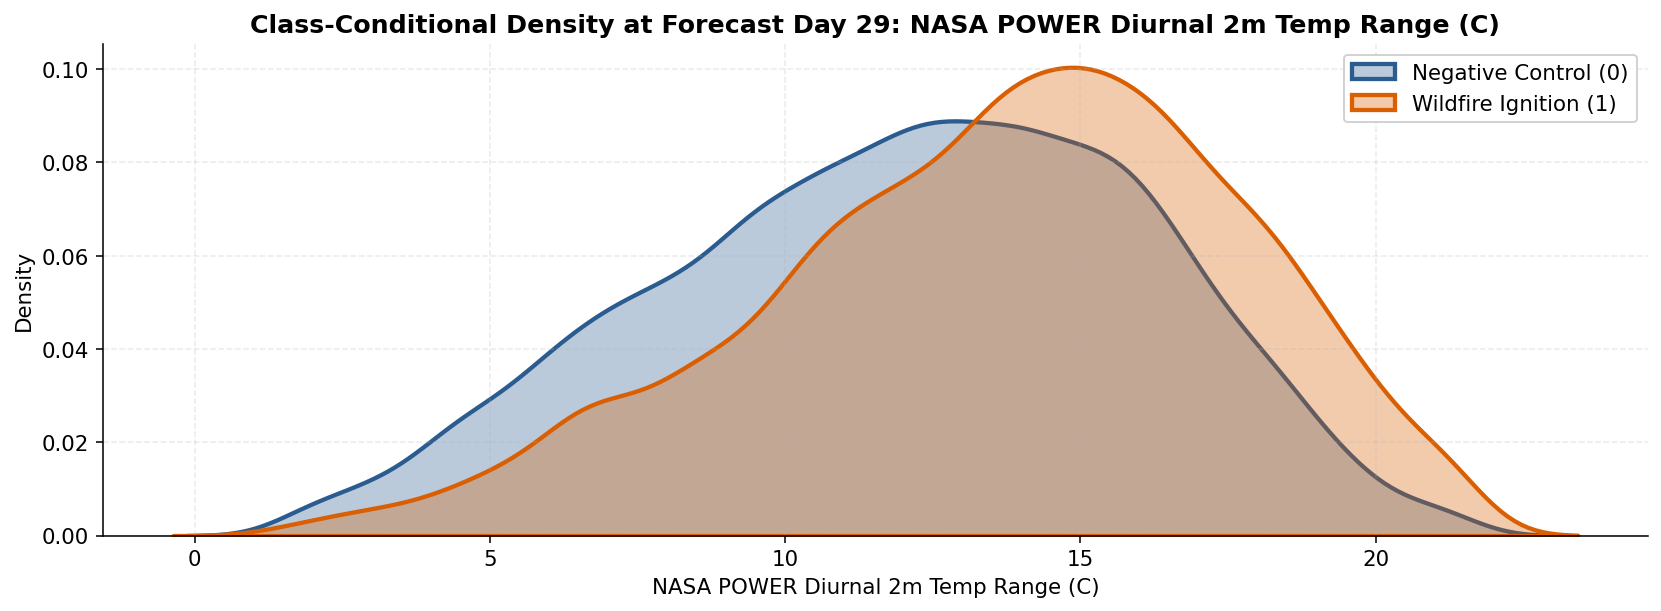

In [21]:
for cname, label_str in CANDIDATE_LABELS.items():
    vals = split_aligned["train"].loc[d29_mask, cname].to_numpy()
    valid_m = np.isfinite(vals)
    v_plot = np.clip(vals[valid_m], np.percentile(vals[valid_m], 0.2), np.percentile(vals[valid_m], 99.5))
    y_plot = d29_y[valid_m]

    fig, ax = plt.subplots(figsize=(12, 4.5))
    sns.kdeplot(v_plot[y_plot == 0], color=PALETTE_CLASS[0], fill=True, alpha=0.32, linewidth=2.2, label="Negative Control (0)", ax=ax)
    sns.kdeplot(v_plot[y_plot == 1], color=PALETTE_CLASS[1], fill=True, alpha=0.32, linewidth=2.2, label="Wildfire Ignition (1)", ax=ax)
    ax.set_xlabel(label_str)
    ax.set_ylabel("Density")
    ax.set_title(f"Class-Conditional Density at Forecast Day 29: {label_str}")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

# 6. Controlled 30-Epoch Ablation Across External ERA5 Predictors

Each of the five external predictors is evaluated independently under the **exact frozen `baseline/train_with_extra.py` pipeline** (`seed=12345`, `epochs=30`, `batch_size=256`, `lr=0.004`, `weight_decay=0.0063`, `StepLR(15, 0.1)`, `dynamic_forecast` mode), selecting the checkpoint with minimum weighted validation loss.

We then compare all models against the 24-variable control using **2,000-resample paired bootstrap confidence intervals** for $\Delta\mathrm{AUPRC} = \mathrm{AUPRC}_{\mathrm{candidate}} - \mathrm{AUPRC}_{\mathrm{control}}$.

In [22]:
RUNS_DIR = WORK / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)
device_arg = "cuda:0" if torch.cuda.is_available() else "cpu"

ablation_summaries = []
ablation_histories = {}
val_predictions = {"control_24var": ctrl_p}

for cname in NASA_VARS:
    out_dir = RUNS_DIR / cname
    c_path = CAND_DIR / cname
    cmd = [
        sys.executable,
        str(BASELINE / "train_with_extra.py"),
        "--mode", "dynamic_forecast",
        "--train-extra", str(c_path / "train_extra.csv"),
        "--validation-extra", str(c_path / "validation_extra.csv"),
        "--output-dir", str(out_dir),
        "--device", device_arg,
    ]
    print(f"Training 30-epoch model with +1 external feature: {cname} ...")
    proc = subprocess.run(cmd, capture_output=True, text=True, check=True)
    for line in proc.stdout.strip().splitlines()[-5:]:
        print("  ", line)

    summ = json.loads((out_dir / "training_summary.json").read_text())
    hist = pd.read_csv(out_dir / "training_history.csv")
    ablation_histories[cname] = hist

    val_extra_ds = ExtraFeatureDataset(
        base_dataset=val_base_ds,
        extra_feature_path=c_path / "validation_extra.csv",
        mode="dynamic_forecast",
    )
    val_loader = DataLoader(val_extra_ds, batch_size=config["training"]["batch_size"], shuffle=False, num_workers=0)
    m_cand = build_model(config, extra_mode="dynamic_forecast").to(DEVICE)
    ckpt = torch.load(out_dir / "model_best_state_dict.pt", map_location=DEVICE, weights_only=True)
    m_cand.load_state_dict(ckpt, strict=True)
    m_cand.eval()

    preds_list = []
    with torch.no_grad():
        for dyn, stat, _lw, _lbl, _sid in val_loader:
            x = prepare_input(dyn, stat, DEVICE)
            probs = torch.softmax(m_cand(x), dim=1)[:, 1]
            preds_list.append(probs.cpu().numpy())
    p_cand = np.concatenate(preds_list)
    val_predictions[cname] = p_cand

    auprc_cand = average_precision_score(ctrl_y, p_cand)
    roc_cand = roc_auc_score(ctrl_y, p_cand)
    brier_cand = brier_score_loss(ctrl_y, p_cand)

    prec_c, rec_c, _ = precision_recall_curve(ctrl_y, p_cand)
    best_f1 = float(np.max(2 * prec_c * rec_c / (prec_c + rec_c + 1e-12)))
    prec_at_r90 = float(prec_c[np.argmin(np.abs(rec_c - 0.90))])

    ablation_summaries.append({
        "Model": cname,
        "Description": CANDIDATE_LABELS[cname],
        "Best Epoch": summ["best_epoch"],
        "Best Val Loss": summ["best_validation_loss"],
        "Val AUPRC": auprc_cand,
        "Delta AUPRC vs Control": auprc_cand - ctrl_val_auprc,
        "Val ROC-AUC": roc_cand,
        "Max F1": best_f1,
        "Precision@90%Recall": prec_at_r90,
        "Brier Score": brier_cand,
    })

prec_0, rec_0, _ = precision_recall_curve(ctrl_y, ctrl_p)
f1_0 = float(np.max(2 * prec_0 * rec_0 / (prec_0 + rec_0 + 1e-12)))
p90_0 = float(prec_0[np.argmin(np.abs(rec_0 - 0.90))])
ablation_summaries.insert(0, {
    "Model": "control_24var",
    "Description": "Official 24-Variable Control Baseline",
    "Best Epoch": control_summary["best_epoch"],
    "Best Val Loss": ctrl_val_loss,
    "Val AUPRC": ctrl_val_auprc,
    "Delta AUPRC vs Control": 0.0,
    "Val ROC-AUC": ctrl_val_roc,
    "Max F1": f1_0,
    "Precision@90%Recall": p90_0,
    "Brier Score": brier_score_loss(ctrl_y, ctrl_p),
})

ablation_df = pd.DataFrame(ablation_summaries).sort_values("Val AUPRC", ascending=False).reset_index(drop=True)
display(ablation_df.round(6))

Training 30-epoch model with +1 external feature: GWETTOP ...
   Best epoch: 17
   Best validation loss: 1.13677895
   Best validation AUPRC: 0.90344410
   Checkpoint: /kaggle/working/runs/GWETTOP/model_best_state_dict.pt
Training 30-epoch model with +1 external feature: GWETROOT ...
   Best epoch: 26
   Best validation loss: 1.12961752
   Best validation AUPRC: 0.90714446
   Checkpoint: /kaggle/working/runs/GWETROOT/model_best_state_dict.pt
Training 30-epoch model with +1 external feature: WS10M_MAX ...
   Best epoch: 26
   Best validation loss: 1.11605854
   Best validation AUPRC: 0.90739977
   Checkpoint: /kaggle/working/runs/WS10M_MAX/model_best_state_dict.pt
Training 30-epoch model with +1 external feature: T2M_RANGE ...
   Best epoch: 26
   Best validation loss: 1.13479940
   Best validation AUPRC: 0.90255717
   Checkpoint: /kaggle/working/runs/T2M_RANGE/model_best_state_dict.pt


,Model,Description,Best Epoch,Best Val Loss,Val AUPRC,Delta AUPRC vs Control,Val ROC-AUC,Max F1,Precision@90%Recall,Brier Score
0,WS10M_MAX,NASA POWER Daily Max 10m Wind Speed (m/s),26,1.116059,0.907400,0.005433,0.947217,0.843137,0.752772,0.085335
1,GWETROOT,NASA POWER Root-Zone Soil Wetness 0-100cm (0-1),26,1.129618,0.907144,0.005178,0.946184,0.831657,0.741266,0.086222
2,GWETTOP,NASA POWER Surface Soil Wetness 0-5cm (0-1),17,1.136779,0.903444,0.001478,0.945414,0.829523,0.750276,0.087333
3,T2M_RANGE,NASA POWER Diurnal 2m Temp Range (C),26,1.134799,0.902557,0.000591,0.945724,0.830284,0.746154,0.087261
4,control_24var,Official 24-Variable Control Baseline,27,1.149052,0.901966,0.000000,0.944725,0.829941,0.751938,0.088826


In [23]:
rng = np.random.default_rng(SEED)
n_val = len(ctrl_y)
n_boot = 2000

boot_deltas = {cname: [] for cname in NASA_VARS}
for _ in range(n_boot):
    idx = rng.integers(0, n_val, size=n_val)
    y_b = ctrl_y[idx]
    if y_b.sum() == 0 or y_b.sum() == n_val:
        continue
    ctrl_b = average_precision_score(y_b, ctrl_p[idx])
    for cname in NASA_VARS:
        cand_b = average_precision_score(y_b, val_predictions[cname][idx])
        boot_deltas[cname].append(cand_b - ctrl_b)

boot_rows = []
for cname, deltas in boot_deltas.items():
    arr = np.asarray(deltas)
    boot_rows.append({
        "Candidate": cname,
        "Mean Delta AUPRC": arr.mean(),
        "CI 2.5%": np.percentile(arr, 2.5),
        "CI 97.5%": np.percentile(arr, 97.5),
        "P(Delta <= 0)": float(np.mean(arr <= 0.0)),
    })

boot_df = pd.DataFrame(boot_rows).sort_values("Mean Delta AUPRC", ascending=False).reset_index(drop=True)
display(boot_df.round(6))

,Candidate,Mean Delta AUPRC,CI 2.5%,CI 97.5%,P(Delta <= 0)
0,WS10M_MAX,0.005534,-0.000788,0.012026,0.0455
1,GWETROOT,0.005240,-0.001216,0.012202,0.0605
2,GWETTOP,0.001537,-0.004976,0.008159,0.3085
3,T2M_RANGE,0.000628,-0.005931,0.007373,0.4230


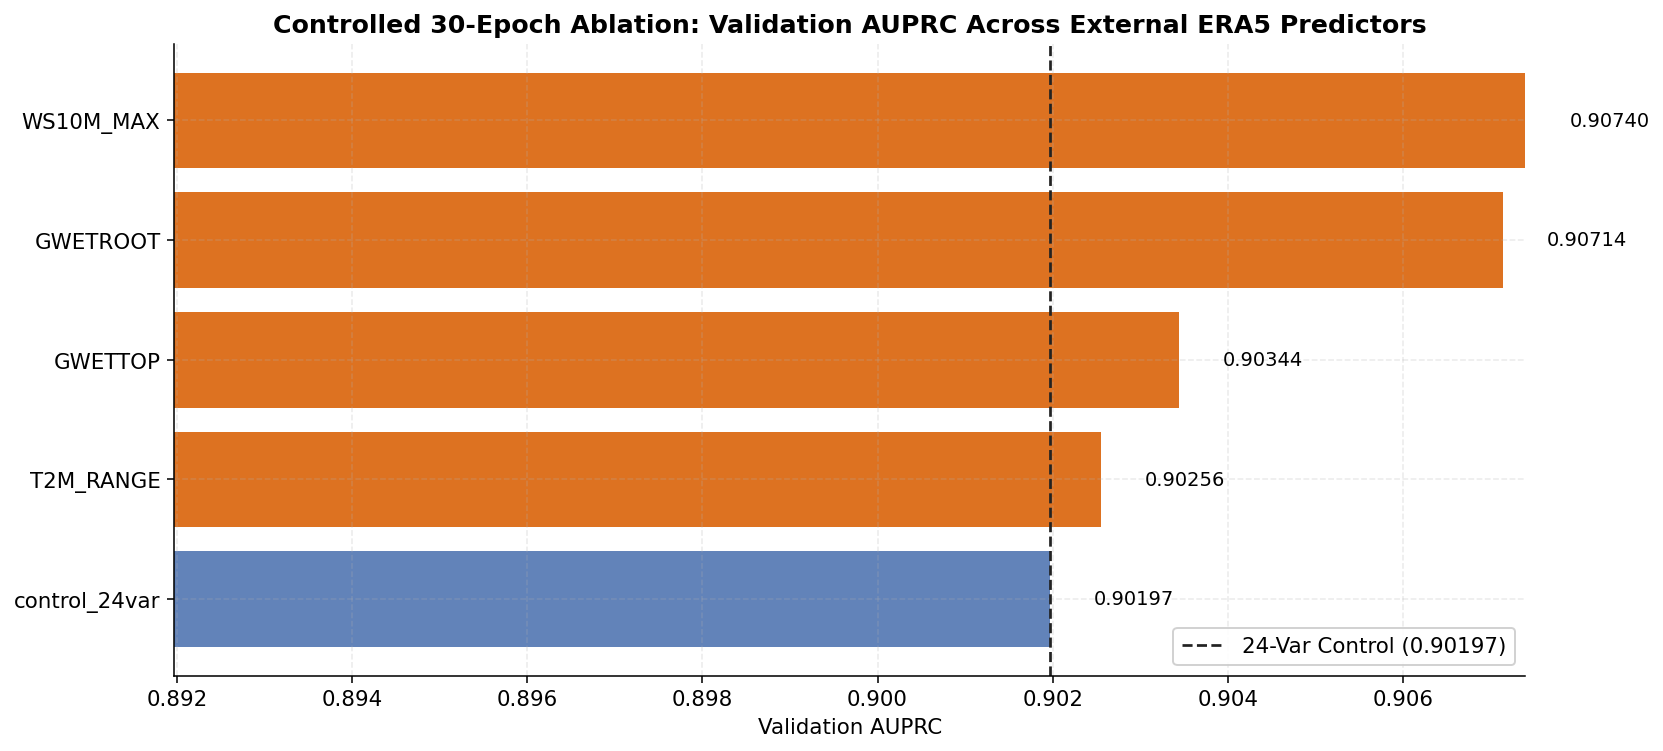

In [24]:
plot_df = ablation_df.sort_values("Val AUPRC", ascending=True)
fig, ax = plt.subplots(figsize=(12, 5.5))
colors_bar = ["#4c72b0" if m == "control_24var" else "#d95f02" for m in plot_df["Model"]]
ax.barh(plot_df["Model"], plot_df["Val AUPRC"], color=colors_bar, alpha=0.88)
ax.axvline(ctrl_val_auprc, color="#222222", linestyle="--", linewidth=1.4, label=f"24-Var Control ({ctrl_val_auprc:.5f})")
min_x = max(0.85, plot_df["Val AUPRC"].min() - 0.01)
ax.set_xlim(min_x, min(1.0, plot_df["Val AUPRC"].max()))
for i, v in enumerate(plot_df["Val AUPRC"]):
    ax.text(v + 0.0005, i, f"{v:.5f}", va="center", fontsize=10)
ax.set_xlabel("Validation AUPRC")
ax.set_title("Controlled 30-Epoch Ablation: Validation AUPRC Across External ERA5 Predictors")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

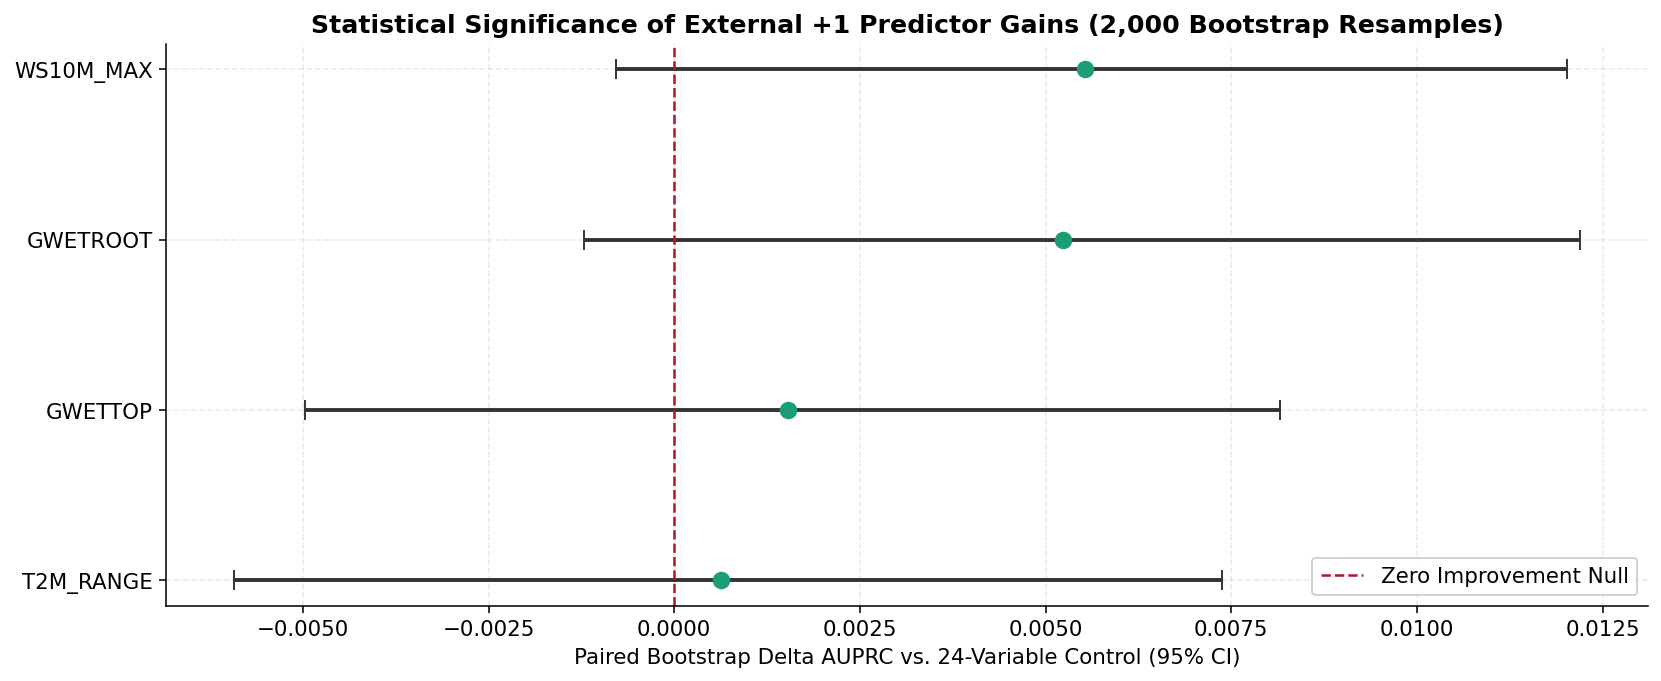

In [25]:
boot_plot = boot_df.sort_values("Mean Delta AUPRC", ascending=True)
fig, ax = plt.subplots(figsize=(12, 5))
y_idx = np.arange(len(boot_plot))
means = boot_plot["Mean Delta AUPRC"].to_numpy()
err_low = means - boot_plot["CI 2.5%"].to_numpy()
err_high = boot_plot["CI 97.5%"].to_numpy() - means
ax.errorbar(means, y_idx, xerr=[err_low, err_high], fmt="o", color="#1b9e77", ecolor="#333333", elinewidth=2.0, capsize=5, markersize=8)
ax.axvline(0.0, color="#b2182b", linestyle="--", linewidth=1.3, label="Zero Improvement Null")
ax.set_yticks(y_idx)
ax.set_yticklabels(boot_plot["Candidate"])
ax.set_xlabel("Paired Bootstrap Delta AUPRC vs. 24-Variable Control (95% CI)")
ax.set_title("Statistical Significance of External +1 Predictor Gains (2,000 Bootstrap Resamples)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

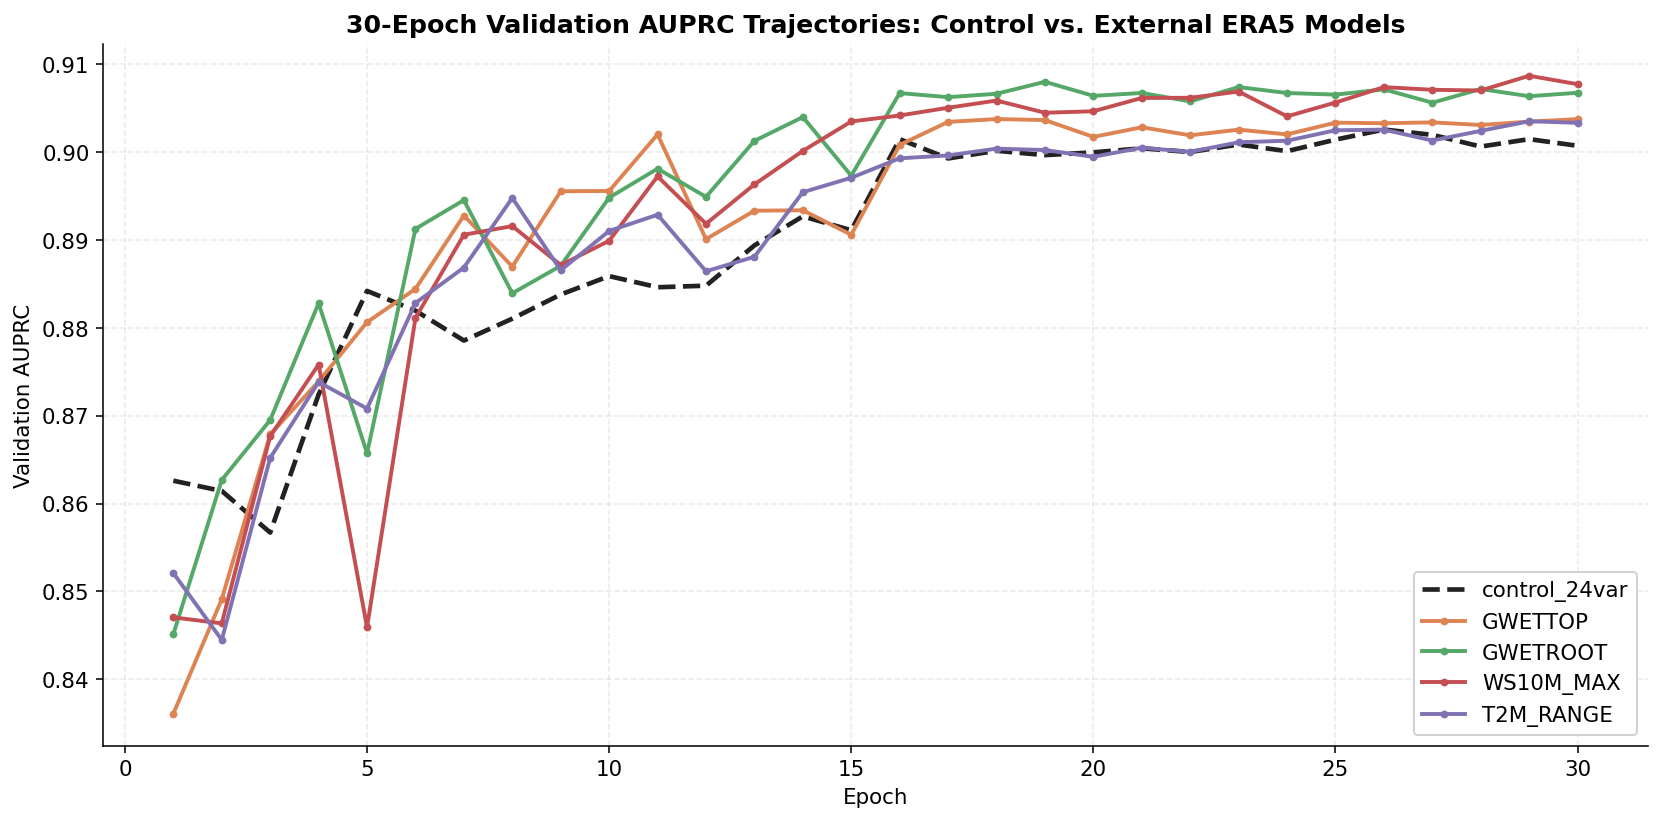

In [26]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(control_history["epoch"], control_history["validation_auprc"], color="#222222", linestyle="--", linewidth=2.4, label="control_24var")
for idx, (cname, hist) in enumerate(ablation_histories.items()):
    ax.plot(hist["epoch"], hist["validation_auprc"], color=PALETTE_MODELS[idx + 1], linewidth=2.0, marker="o", markersize=3, label=cname)
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation AUPRC")
ax.set_title("30-Epoch Validation AUPRC Trajectories: Control vs. External ERA5 Models")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 7. Deep Diagnostics, Calibration, and Temporal Attribution of the Winning +1 Model

We select the external predictor achieving the highest validation AUPRC (breaking ties by minimum weighted validation loss) and evaluate its Precision-Recall curve, ROC curve, 10-bin calibration reliability, stratified seasonal/land-cover gains, and Gradient $\times$ Input attributions:

$$A_{t,f} = \frac{1}{N_{\mathrm{val}}} \sum_{i=1}^{N_{\mathrm{val}}} \left| x_{i,t,f} \cdot \frac{\partial z_{i,1}}{\partial x_{i,t,f}} \right|$$

In [27]:
cand_only = ablation_df[ablation_df["Model"] != "control_24var"].sort_values(
    ["Val AUPRC", "Best Val Loss"], ascending=[False, True]
)
BEST_NAME = cand_only.iloc[0]["Model"]
BEST_DESC = CANDIDATE_LABELS[BEST_NAME]
BEST_PROBS = val_predictions[BEST_NAME]
BEST_DIR = RUNS_DIR / BEST_NAME
BEST_HIST = ablation_histories[BEST_NAME]

print(f"Selected Winning +1 External Variable: {BEST_NAME} ({BEST_DESC})")
print(f"Winning Validation AUPRC:              {cand_only.iloc[0]['Val AUPRC']:.8f}")
print(f"Control Validation AUPRC:              {ctrl_val_auprc:.8f}")
print(f"Net Improvement (Delta):               {cand_only.iloc[0]['Delta AUPRC vs Control']:+.8f}")

Selected Winning +1 External Variable: WS10M_MAX (NASA POWER Daily Max 10m Wind Speed (m/s))
Winning Validation AUPRC:              0.90739977
Control Validation AUPRC:              0.90196645
Net Improvement (Delta):               +0.00543332


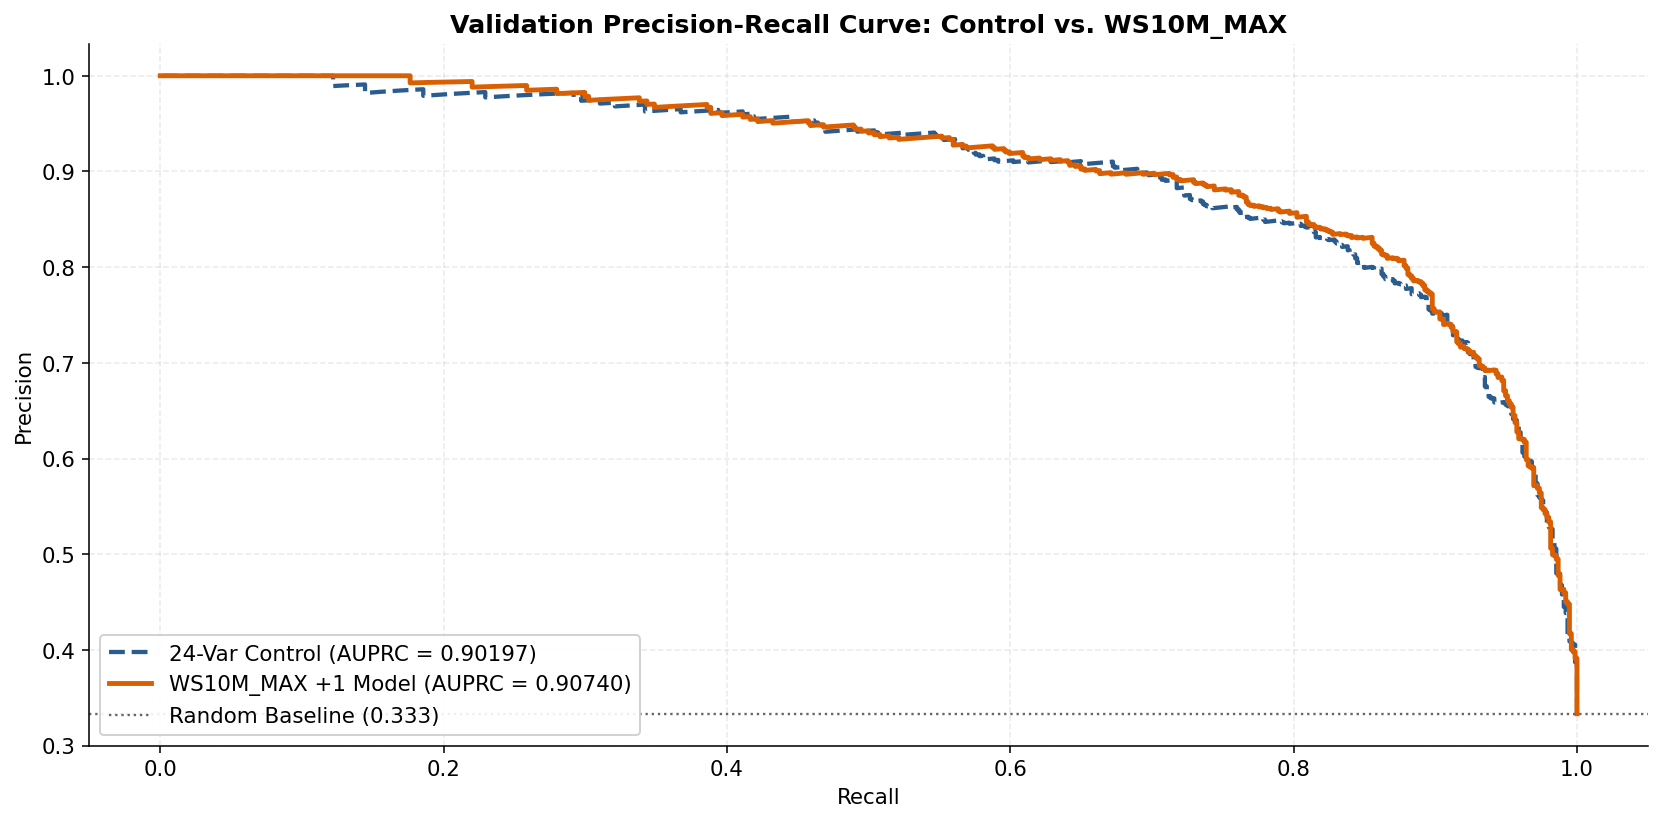

In [28]:
prec_ctrl, rec_ctrl, _ = precision_recall_curve(ctrl_y, ctrl_p)
prec_best, rec_best, _ = precision_recall_curve(ctrl_y, BEST_PROBS)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(rec_ctrl, prec_ctrl, color="#2b5c8f", linewidth=2.2, linestyle="--", label=f"24-Var Control (AUPRC = {ctrl_val_auprc:.5f})")
ax.plot(rec_best, prec_best, color="#d95f02", linewidth=2.5, label=f"{BEST_NAME} +1 Model (AUPRC = {average_precision_score(ctrl_y, BEST_PROBS):.5f})")
ax.axhline(ctrl_y.mean(), color="#666666", linestyle=":", linewidth=1.2, label=f"Random Baseline ({ctrl_y.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(f"Validation Precision-Recall Curve: Control vs. {BEST_NAME}")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

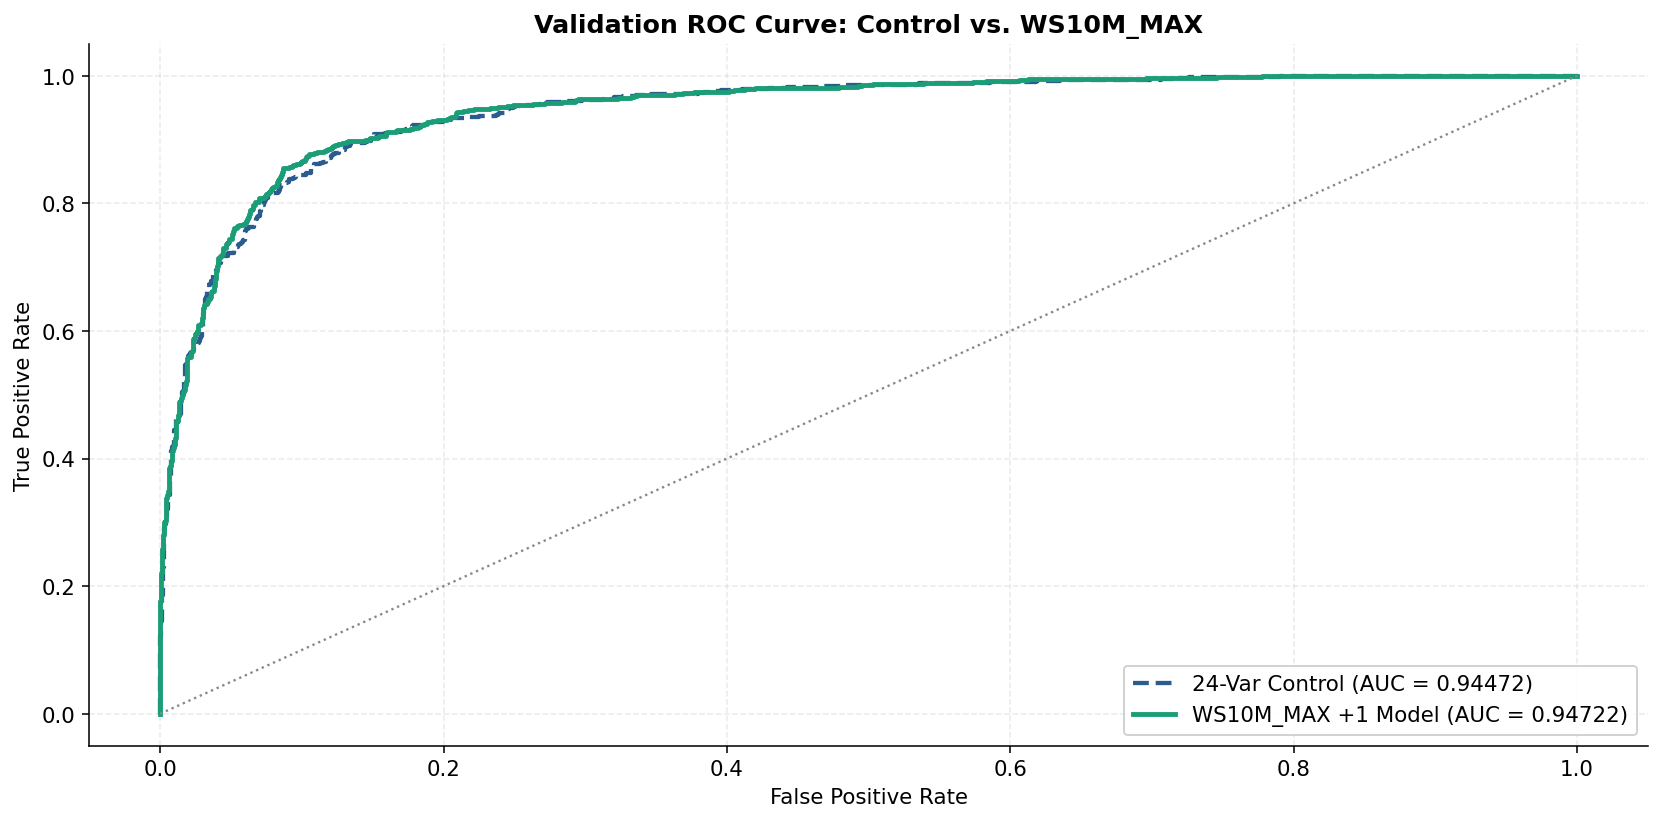

In [29]:
fpr_ctrl, tpr_ctrl, _ = roc_curve(ctrl_y, ctrl_p)
fpr_best, tpr_best, _ = roc_curve(ctrl_y, BEST_PROBS)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(fpr_ctrl, tpr_ctrl, color="#2b5c8f", linewidth=2.2, linestyle="--", label=f"24-Var Control (AUC = {ctrl_val_roc:.5f})")
ax.plot(fpr_best, tpr_best, color="#1b9e77", linewidth=2.5, label=f"{BEST_NAME} +1 Model (AUC = {roc_auc_score(ctrl_y, BEST_PROBS):.5f})")
ax.plot([0, 1], [0, 1], color="#888888", linestyle=":", linewidth=1.2)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(f"Validation ROC Curve: Control vs. {BEST_NAME}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

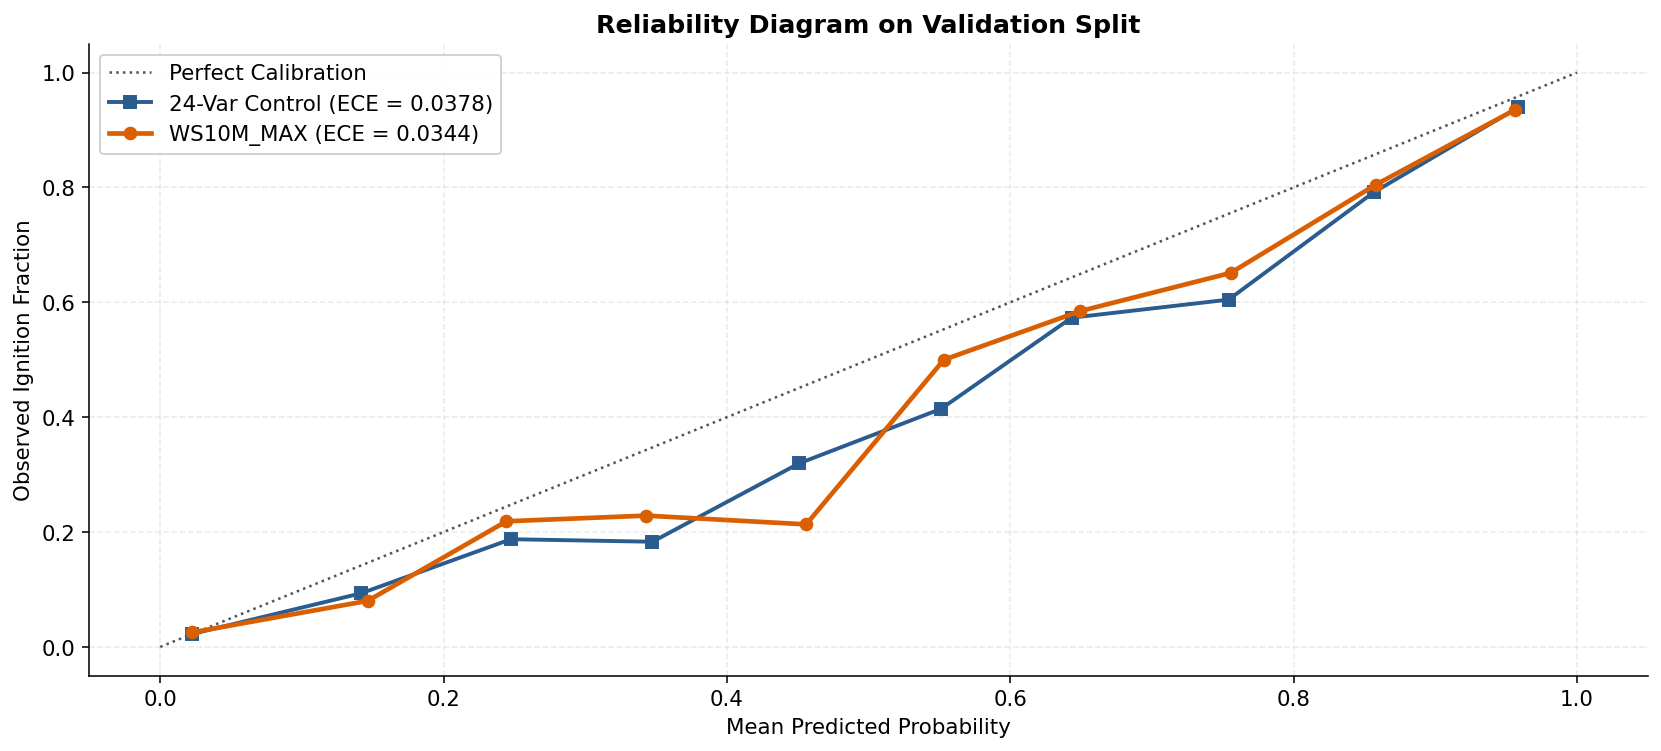

In [30]:
n_bins = 10
bins = np.linspace(0.0, 1.0, n_bins + 1)

def calibration_stats(y_true, y_prob):
    bin_ids = np.digitize(y_prob, bins[1:-1], right=True)
    mean_pred, frac_pos, counts = [], [], []
    for b in range(n_bins):
        m = bin_ids == b
        if m.sum() > 0:
            mean_pred.append(y_prob[m].mean())
            frac_pos.append(y_true[m].mean())
            counts.append(m.sum())
    ece = sum(c * abs(fp - mp) for mp, fp, c in zip(mean_pred, frac_pos, counts)) / len(y_true)
    return np.array(mean_pred), np.array(frac_pos), ece

mp_c, fp_c, ece_c = calibration_stats(ctrl_y, ctrl_p)
mp_b, fp_b, ece_b = calibration_stats(ctrl_y, BEST_PROBS)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot([0, 1], [0, 1], color="#555555", linestyle=":", linewidth=1.3, label="Perfect Calibration")
ax.plot(mp_c, fp_c, marker="s", color="#2b5c8f", linewidth=2.0, label=f"24-Var Control (ECE = {ece_c:.4f})")
ax.plot(mp_b, fp_b, marker="o", color="#d95f02", linewidth=2.4, label=f"{BEST_NAME} (ECE = {ece_b:.4f})")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Ignition Fraction")
ax.set_title("Reliability Diagram on Validation Split")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

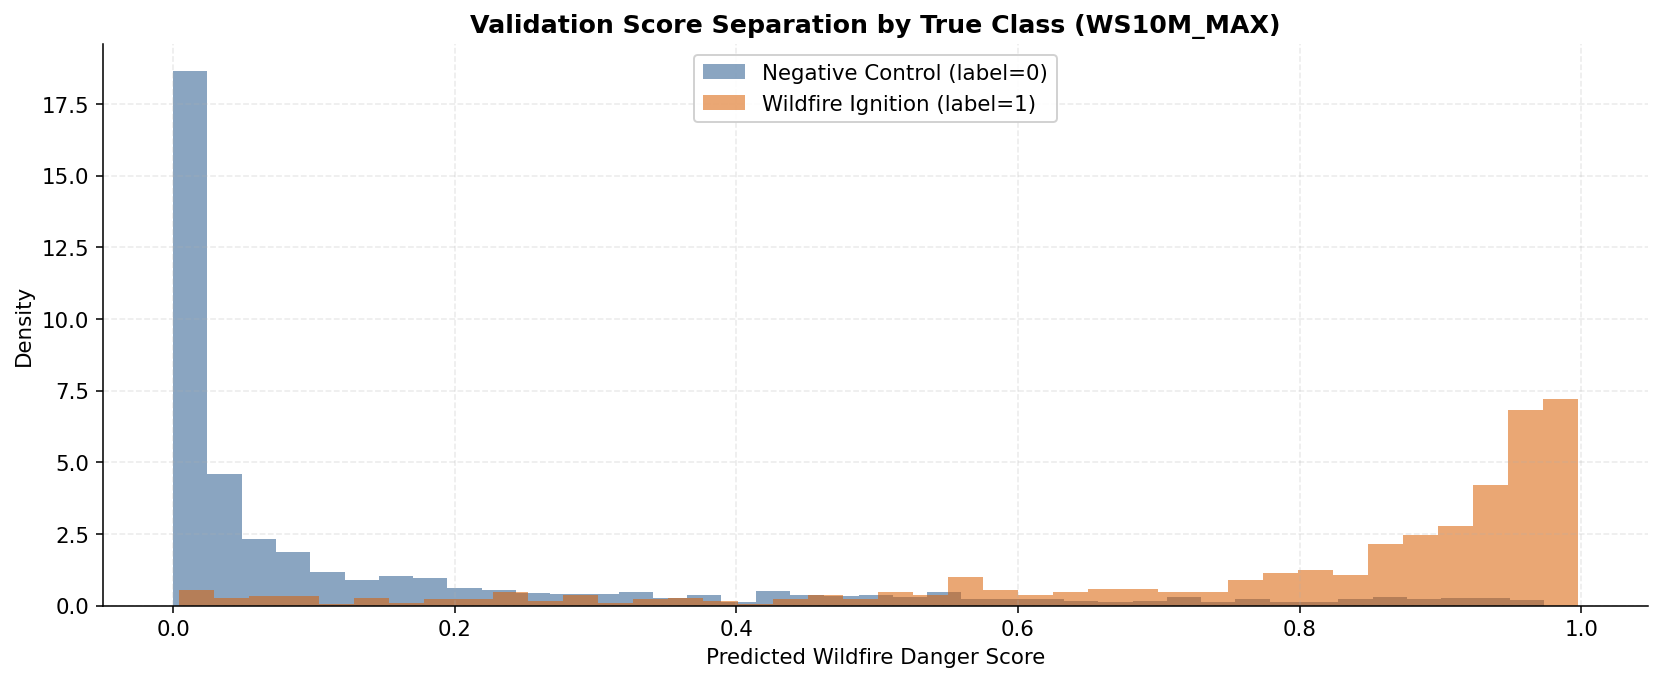

In [31]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(BEST_PROBS[ctrl_y == 0], bins=40, density=True, alpha=0.55, color=PALETTE_CLASS[0], label="Negative Control (label=0)")
ax.hist(BEST_PROBS[ctrl_y == 1], bins=40, density=True, alpha=0.55, color=PALETTE_CLASS[1], label="Wildfire Ignition (label=1)")
ax.set_xlabel("Predicted Wildfire Danger Score")
ax.set_ylabel("Density")
ax.set_title(f"Validation Score Separation by True Class ({BEST_NAME})")
ax.legend(loc="upper center")
plt.tight_layout()
plt.show()

,Stratum,Samples,Pos Rate,Control AUPRC,Winning AUPRC,Delta AUPRC
0,season: Off-Peak (Oct-May),943,0.12619,0.78880,0.80511,0.01630
1,season: Peak Fire Season (Jun-Sep),1319,0.48143,0.91940,0.92265,0.00324
2,dom_lc: lc_agriculture,996,0.31325,0.88131,0.88845,0.00714
3,dom_lc: lc_forest,927,0.37648,0.92955,0.93755,0.00800
4,dom_lc: lc_grassland,89,0.55056,0.95475,0.95113,-0.00362
5,dom_lc: lc_shrubland,250,0.17600,0.72624,0.71354,-0.01271


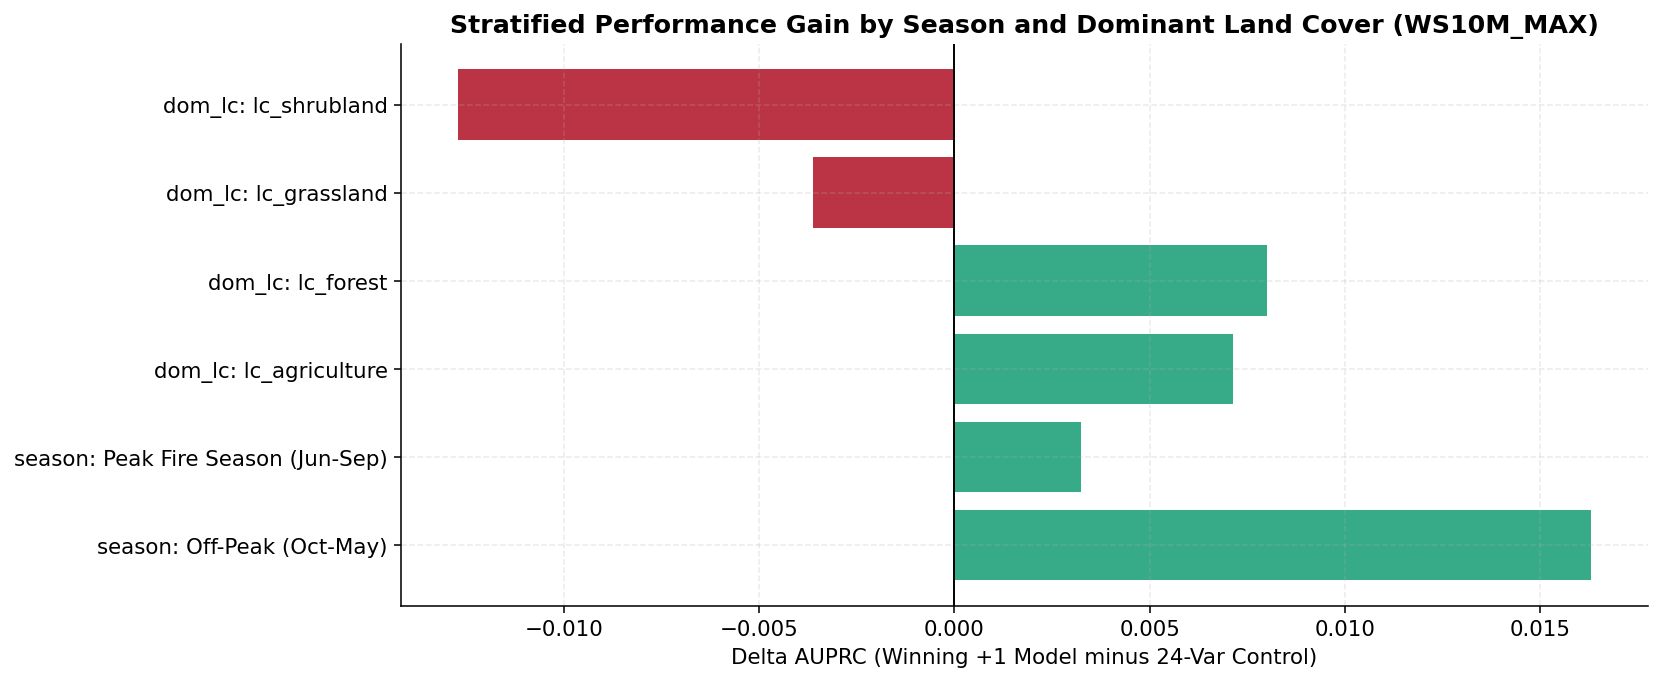

In [32]:
val_eval = val_d29[["competition_id", "latitude", "time_dt", "lc_forest", "lc_shrubland", "lc_agriculture", "lc_grassland"]].copy()
val_eval["y"] = ctrl_y
val_eval["p_ctrl"] = ctrl_p
val_eval["p_best"] = BEST_PROBS
val_eval["month"] = val_eval["time_dt"].dt.month
val_eval["season"] = np.where(val_eval["month"].isin([6, 7, 8, 9]), "Peak Fire Season (Jun-Sep)", "Off-Peak (Oct-May)")
lc_cols = ["lc_forest", "lc_shrubland", "lc_agriculture", "lc_grassland"]
val_eval["dom_lc"] = val_eval[lc_cols].idxmax(axis=1)

strat_rows = []
for grp_col in ["season", "dom_lc"]:
    for gname, gdf in val_eval.groupby(grp_col):
        if gdf["y"].nunique() < 2 or len(gdf) < 30:
            continue
        a_c = average_precision_score(gdf["y"], gdf["p_ctrl"])
        a_b = average_precision_score(gdf["y"], gdf["p_best"])
        strat_rows.append({
            "Stratum": f"{grp_col}: {gname}",
            "Samples": len(gdf),
            "Pos Rate": gdf["y"].mean(),
            "Control AUPRC": a_c,
            "Winning AUPRC": a_b,
            "Delta AUPRC": a_b - a_c,
        })

strat_df = pd.DataFrame(strat_rows)
display(strat_df.round(5))

fig, ax = plt.subplots(figsize=(12, 5))
colors_strat = ["#1b9e77" if d >= 0 else "#b2182b" for d in strat_df["Delta AUPRC"]]
ax.barh(strat_df["Stratum"], strat_df["Delta AUPRC"], color=colors_strat, alpha=0.88)
ax.axvline(0.0, color="black", linewidth=1.0)
ax.set_xlabel("Delta AUPRC (Winning +1 Model minus 24-Var Control)")
ax.set_title(f"Stratified Performance Gain by Season and Dominant Land Cover ({BEST_NAME})")
plt.tight_layout()
plt.show()

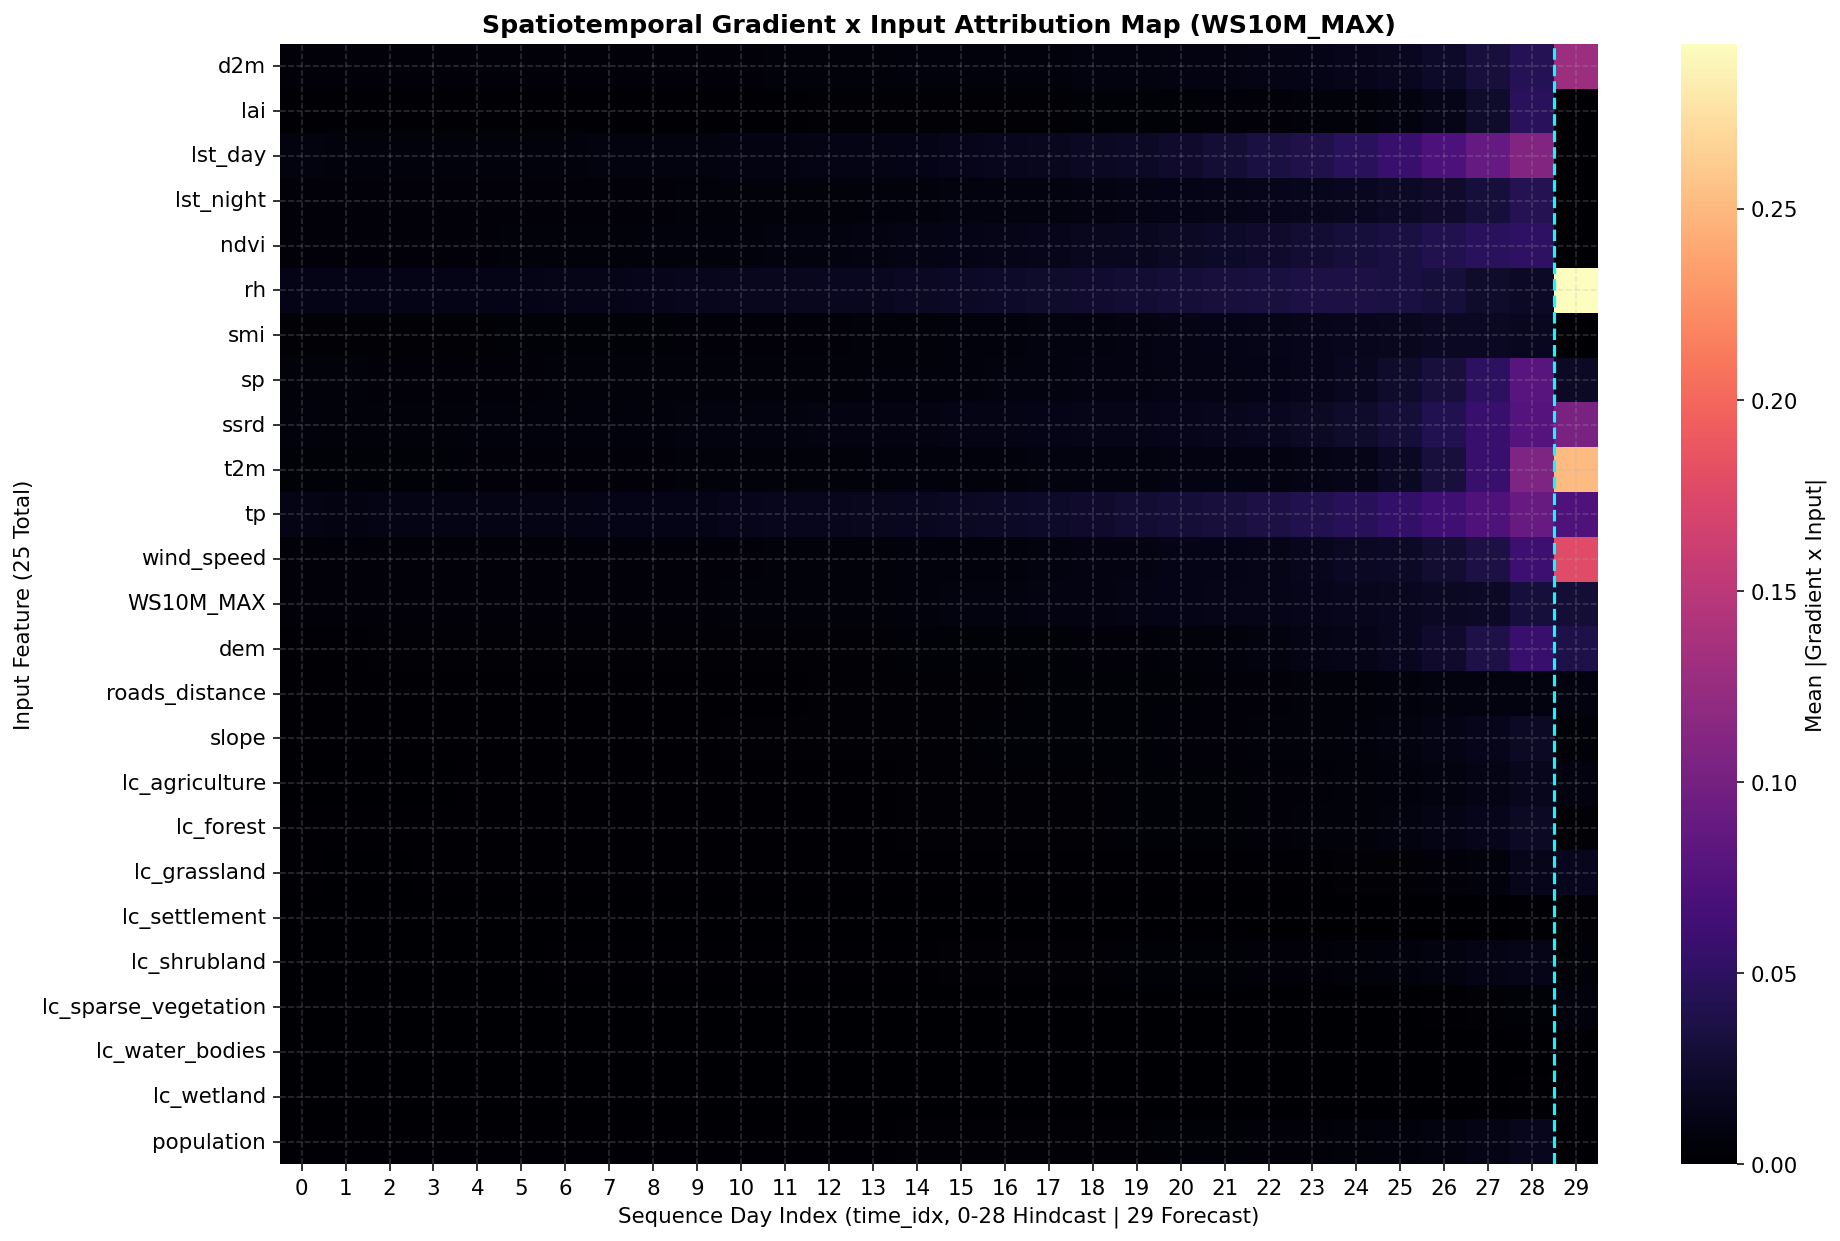

In [33]:
best_val_ds = ExtraFeatureDataset(
    base_dataset=val_base_ds,
    extra_feature_path=CAND_DIR / BEST_NAME / "validation_extra.csv",
    mode="dynamic_forecast",
)
best_val_loader = DataLoader(best_val_ds, batch_size=config["training"]["batch_size"], shuffle=False, num_workers=0)

best_model = build_model(config, extra_mode="dynamic_forecast").to(DEVICE)
best_ckpt = torch.load(BEST_DIR / "model_best_state_dict.pt", map_location=DEVICE, weights_only=True)
best_model.load_state_dict(best_ckpt, strict=True)
best_model.train()
for mod in best_model.modules():
    if isinstance(mod, torch.nn.Dropout):
        mod.eval()

attr_sum = np.zeros((30, 25), dtype=np.float64)
n_attr = 0

for dyn, stat, _lw, _lbl, _sid in best_val_loader:
    x = prepare_input(dyn, stat, DEVICE).detach().requires_grad_(True)
    logits = best_model(x)
    target_logit = logits[:, 1].sum()
    best_model.zero_grad()
    target_logit.backward()
    grad_x = (x * x.grad).abs().detach().cpu().numpy()
    attr_sum += grad_x.sum(axis=0)
    n_attr += grad_x.shape[0]

attr_mean = attr_sum / n_attr
feature_names_25 = config["dynamic_features"] + [BEST_NAME] + config["static_features"]

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(
    attr_mean.T,
    yticklabels=feature_names_25,
    xticklabels=list(range(30)),
    cmap="magma",
    cbar_kws={"label": "Mean |Gradient x Input|"},
    ax=ax,
)
ax.axvline(29, color="#00ffff", linestyle="--", linewidth=1.6)
ax.set_xlabel("Sequence Day Index (time_idx, 0-28 Hindcast | 29 Forecast)")
ax.set_ylabel("Input Feature (25 Total)")
ax.set_title(f"Spatiotemporal Gradient x Input Attribution Map ({BEST_NAME})")
plt.tight_layout()
plt.show()

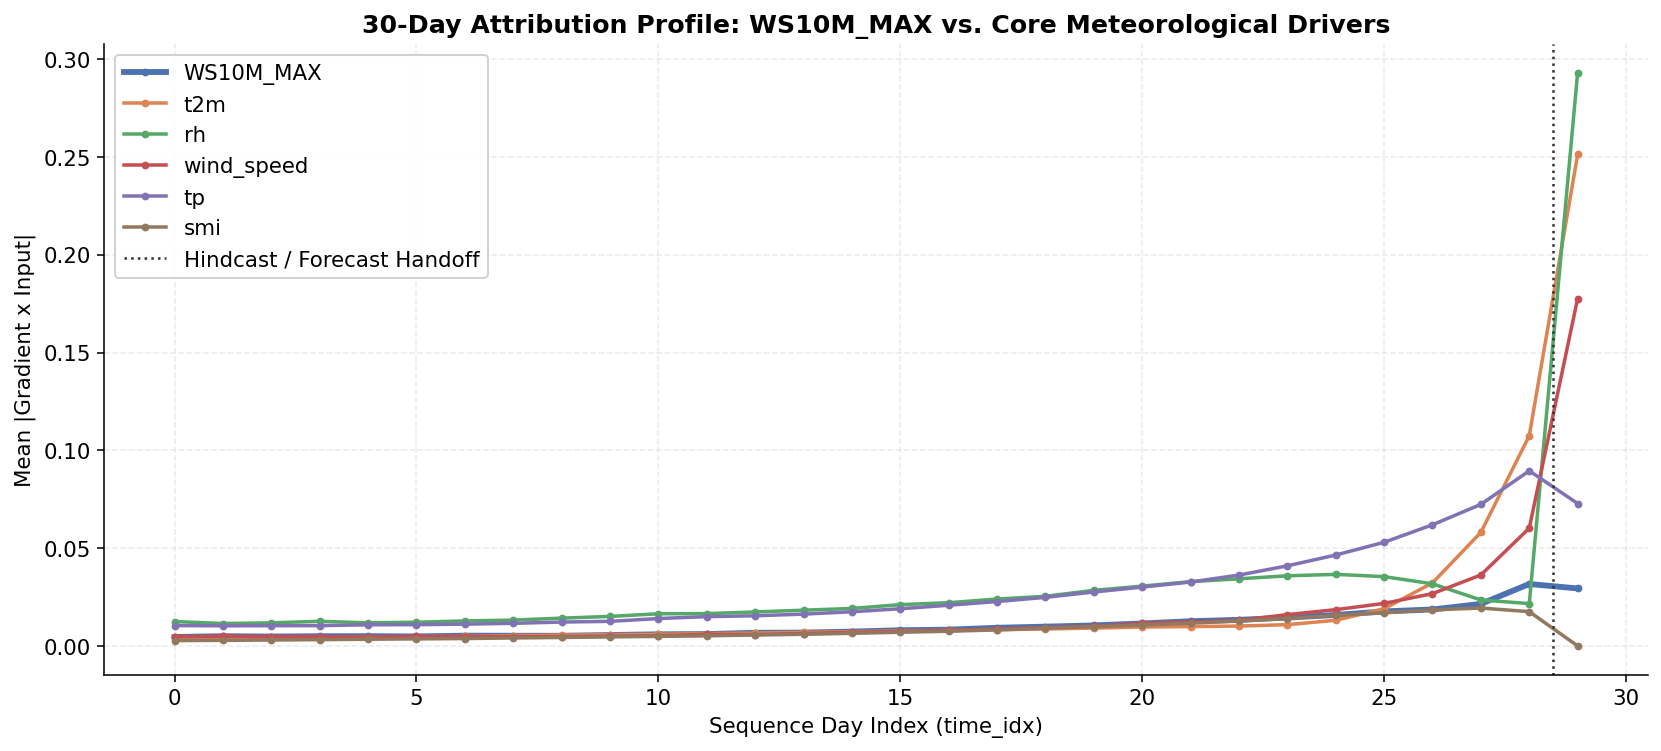

In [34]:
top_dyn_idx = [feature_names_25.index(f) for f in [BEST_NAME, "t2m", "rh", "wind_speed", "tp", "smi"]]
fig, ax = plt.subplots(figsize=(12, 5.5))
for idx_f, c_hex in zip(top_dyn_idx, PALETTE_MODELS):
    lw = 3.0 if feature_names_25[idx_f] == BEST_NAME else 1.8
    ax.plot(range(30), attr_mean[:, idx_f], label=feature_names_25[idx_f], color=c_hex, linewidth=lw, marker="o", markersize=3)
ax.axvline(28.5, color="#333333", linestyle=":", linewidth=1.3, label="Hindcast / Forecast Handoff")
ax.set_xlabel("Sequence Day Index (time_idx)")
ax.set_ylabel("Mean |Gradient x Input|")
ax.set_title(f"30-Day Attribution Profile: {BEST_NAME} vs. Core Meteorological Drivers")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 8. Final Submission Generation and Verification

We invoke the frozen `baseline/predict_with_extra.py` script using the winning candidate's `model_best_state_dict.pt` and `test_extra.csv` to produce `/kaggle/working/submission.csv`, verify all schema invariants (`4,107` rows, exact `competition_id` alignment, zero NaNs, strict $[0, 1]$ range), and compare the test score distribution against the validation score distribution.

In [35]:
SUBMISSION_PATH = WORK / "submission.csv"

pred_cmd = [
    sys.executable,
    str(BASELINE / "predict_with_extra.py"),
    "--mode", "dynamic_forecast",
    "--extra", str(CAND_DIR / BEST_NAME / "test_extra.csv"),
    "--checkpoint", str(BEST_DIR / "model_best_state_dict.pt"),
    "--output", str(SUBMISSION_PATH),
    "--device", device_arg,
]
pred_proc = subprocess.run(pred_cmd, capture_output=True, text=True, check=True)
print(pred_proc.stdout)

sub_df = pd.read_csv(SUBMISSION_PATH)
assert list(sub_df.columns) == ["competition_id", "prediction"]
assert len(sub_df) == 4107, f"Expected 4,107 rows, got {len(sub_df)}"
assert sub_df["competition_id"].tolist() == sample_sub["competition_id"].tolist()
assert sub_df["prediction"].notna().all()
assert sub_df["prediction"].between(0.0, 1.0, inclusive="both").all()

print("Submission verification PASSED.")
print(sub_df["prediction"].describe().round(5))
display(sub_df.head(10))

Mode: dynamic_forecast
Device: cuda:0
Checkpoint: <All keys matched successfully>
Saved 4,107 predictions:
/kaggle/working/submission.csv

Submission verification PASSED.
count    4107.00000
mean        0.37239
std         0.37968
min         0.00004
25%         0.01707
50%         0.19269
75%         0.79240
max         0.99880
Name: prediction, dtype: float64


,competition_id,prediction
0,TE000001,0.000217
1,TE000002,0.954036
2,TE000003,0.965837
3,TE000004,0.009615
4,TE000005,0.676068
5,TE000006,0.366005
6,TE000007,0.025829
7,TE000008,0.381988
8,TE000009,0.030255
9,TE000010,0.001884


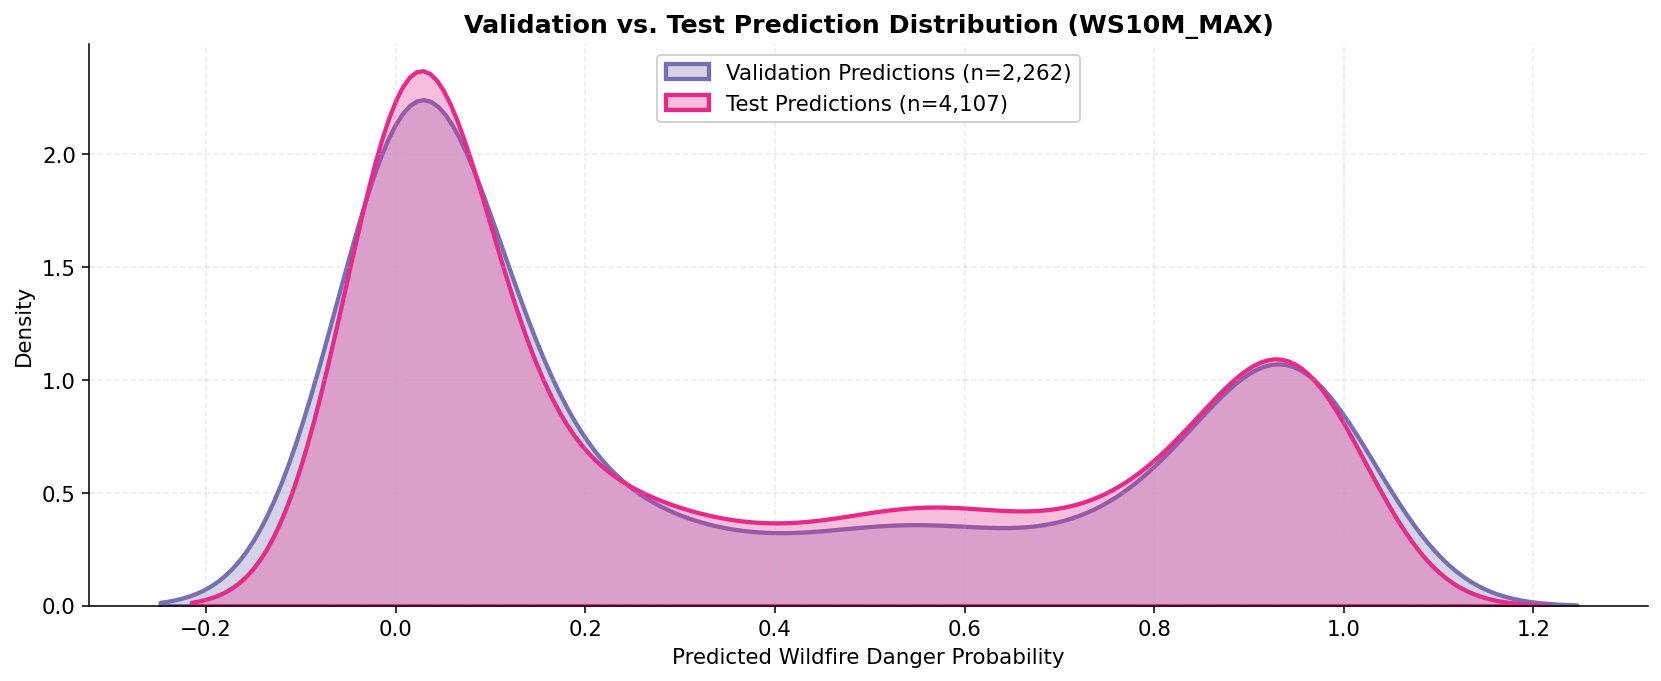

In [36]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.kdeplot(BEST_PROBS, color=PALETTE_SPLITS["Validation"], fill=True, alpha=0.30, linewidth=2.2, label="Validation Predictions (n=2,262)")
sns.kdeplot(sub_df["prediction"].to_numpy(), color=PALETTE_SPLITS["Test"], fill=True, alpha=0.30, linewidth=2.2, label="Test Predictions (n=4,107)")
ax.set_xlabel("Predicted Wildfire Danger Probability")
ax.set_ylabel("Density")
ax.set_title(f"Validation vs. Test Prediction Distribution ({BEST_NAME})")
ax.legend(loc="upper center")
plt.tight_layout()
plt.show()